# Transfer learning: ResNet-18 и MobileNetV2

В этот раз мы продолжим работать с изображениями и обсудим, как адаптировать уже обученные
модели под свои задачи. Но сначала разберём, из чего состоит современная свёрточная сеть
и зачем ей **global average pooling**, **batch normalization** и **residual connections**.

План практики:
1. **ResNet изнутри** — почему глубокие сети не обучаются без residual connections,
   зачем нужны BatchNorm и global average pooling, и как из этих же идей собирается
   лёгкая MobileNet (depthwise separable свёртки, inverted residual);
2. **Инструменты** — обучающий цикл на чистом PyTorch, метрики `torchmetrics` и замер
   времени обучения и инференса;
3. **Стратегии переноса знаний** — серия экспериментов на Oxford-IIIT Pet: от обучения
   с нуля до полного файнтюна; в каждом меняем ровно одну вещь; каждый эксперимент
   повторяем на двух бэкбонах — тяжёлом ResNet-18 и лёгком MobileNetV2 — и сравниваем
   качество, время обучения и скорость инференса;
4. **Аугментации** — когда они помогают, а когда бесполезны;
5. **Типичные ошибки** — как по кривым обучения и быстрым проверкам поймать частые
   баги при дизайне и реализации таких сетей.

Полезные ссылки:
- [ResNet: Deep Residual Learning (статья)](https://arxiv.org/abs/1512.03385)
- [MobileNetV2: Inverted Residuals and Linear Bottlenecks (статья)](https://arxiv.org/abs/1801.04381)

In [1]:
# --- стандартные библиотеки ---
import copy  # deepcopy: шаги 3 и 5 стартуют с копией модели, обученной на шаге 2
import time  # замер времени обучения и инференса
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchmetrics
import tqdm.auto
from IPython.display import Image, display
from PIL import Image as PILImage
from torch import nn
from torchvision import transforms
from torchvision.models import MobileNet_V2_Weights, ResNet18_Weights, mobilenet_v2, resnet18

from utils.common import seed_everything
from utils.plotting import plot_train_history, show_image_batch
from utils.plotting import IMAGENET_MEAN, IMAGENET_STD

from utils.data import make_dataloaders
%matplotlib inline
warnings.filterwarnings("ignore")

seed_everything(123)  # фиксируем случайности: все стратегии обучаются при прочих равных

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch: {torch.__version__}, device: {device}")
if device.type == "cuda":
    print(f"gpu: {torch.cuda.get_device_name(0)}")

torch: 2.14.1+cpu, device: cpu


## Данные: Oxford-IIIT Pet

В этой практике рассмотрим [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) — датасет, содержащий 37 классов пород кошек и
собак, ~3.7 тысяч обучающих изображений (около 100 на класс).

Мы сталкиваемся с двумя проблемами сразу:
- датасет достаточно маленький, и информации по каждому классу не очень много.
- даже с учетом этого обучить модель с нуля может быть сложно

Картинки при этом довольно похожи на «обычные» фотографии, поэтому можно перенести знания какой-нибудь мощной модели, обученной на большом датасете, на нашу задачу. Чаще всего для этого
используется файн-тюнинг: модель, обученная на большом датасете, уже умеет выделять хорошие признаки из изображений — возьмём её веса и слегка подстроим под новую задачу.


In [3]:
train_loader, val_loader, test_loader, num_classes, classes = make_dataloaders(batch_size=64)

print(f"train: {len(train_loader.dataset)} | val: {len(val_loader.dataset)} | test: {len(test_loader.dataset)}")
print(f"классов: {num_classes}, первые 5: {classes[:5]}")


100%|██████████| 792M/792M [11:02<00:00, 1.19MB/s]  
100%|██████████| 19.2M/19.2M [00:21<00:00, 899kB/s] 


train: 2944 | val: 736 | test: 3669
классов: 37, первые 5: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


saved: ..\images\dataset_samples.png


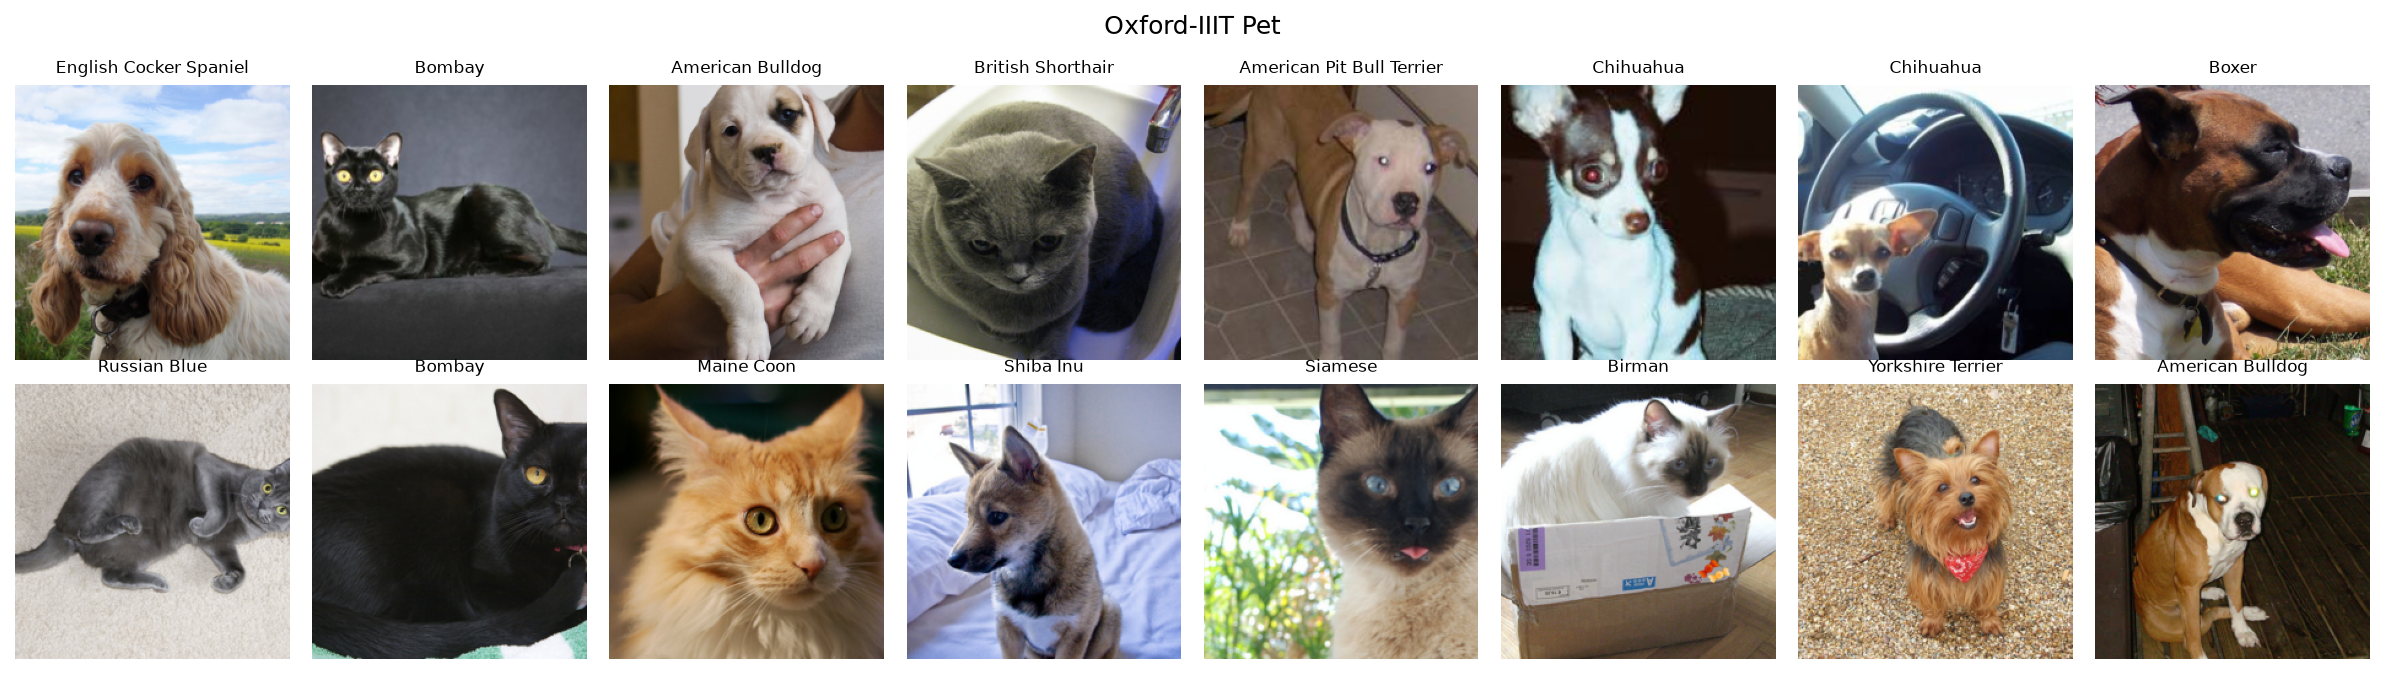

In [4]:

images, labels = next(iter(train_loader))
show_image_batch(
    images, labels, classes,
    save_path="../images/dataset_samples.png",
    title="Oxford-IIIT Pet",
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD,
)
display(Image(filename="../images/dataset_samples.png"))


*Задание*: выведите случайный элемент датасета. 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..0.9764706132411958].


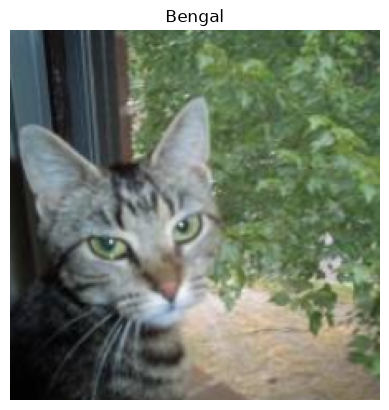

In [5]:
import random
img, label = train_loader.dataset[random.randint(0, len(train_loader.dataset) - 1)]
plt.imshow(img.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN)
plt.title(classes[label]); plt.axis("off"); plt.show()

## Предобученные модели
В `torchvision` реализовано множество моделей (ResNet, VGG, AlexNet, DenseNet, ResNext, WideResNet, MobileNet, ...) вместе с чекпоинтами на ImageNet — см. [документацию моделей](https://pytorch.org/vision/stable/models.html). ImageNet - это огромный датасте на 1000 классов, который долгое время использовался как основвное средство для получения достаточно сильных моделей и их сравнения.

Для начала загрузим модель ResNet-18.

In [6]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
model = model.to(device)
model.eval()  # почему это важно?

print(f"всего параметров: {sum(p.numel() for p in model.parameters()):,}")
print(f"модель на устройстве: {next(model.parameters()).device}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\2005k/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:05<00:00, 9.28MB/s]


всего параметров: 11,689,512
модель на устройстве: cpu


Несмотря на то, что эта модель считается достаточно простой и маленькой, у нее уже 11 миллионов параметров, обучать ее может быть непросто. Нол попробуем проверить, может, модель изначально ничего. 

In [7]:
def predict_imagenet(model, x: torch.Tensor, top_n: int = 5):

    with torch.no_grad():
        logits = model(x.float())
    probs = torch.softmax(logits, dim=-1)[0].cpu()  # вероятности по 1000 классам, не нашим!
    categories = ResNet18_Weights.DEFAULT.meta["categories"]
    top = probs.topk(top_n)
    return {categories[int(idx)]: float(prob) for prob, idx in zip(top.values, top.indices)}

Сделаем предсказания на случайных картинках:

In [8]:

idx = np.random.randint(len(train_loader.dataset))

# препроцессинг делается как при обучении : масштаб -> центральный кроп 224x224 ->
# тензор [0, 1] -> нормализация статистиками ImageNet

image, label = train_loader.dataset[idx] 
image = image.to(device).unsqueeze(0)
print(f"истинный класс: {classes[label]}")
predict_imagenet(model, image)


истинный класс: Staffordshire Bull Terrier


{'Staffordshire bullterrier': 0.789766252040863,
 'American Staffordshire terrier': 0.1439514458179474,
 'Boston bull': 0.03400597721338272,
 'boxer': 0.025867028161883354,
 'basenji': 0.002934453310444951}

*Задание*: попробуйте свои картинки. Сделайте препроцессинг, соответствующий Imagenet. Ответьте, как отличается уверенность модели для классов, близких к imagenet и далеких от него.


In [13]:
preprocess = ResNet18_Weights.DEFAULT.transforms()   
x = preprocess(PILImage.open("../images/kitten.jpg").convert("RGB")).unsqueeze(0).to(device)
predict_imagenet(model, x)

{'ping-pong ball': 0.11492374539375305,
 'pill bottle': 0.0954635813832283,
 'Angora': 0.0505681112408638,
 'fur coat': 0.030753077939152718,
 'lab coat': 0.025960197672247887}

## ResNet

### Проблема глубины

Исследователи заметили: чем глубже свёрточная сеть, тем лучше — гибкость модели растёт с числом параметров. Но начиная с некоторой глубины точность перестаёт расти и начинает **падать**
(причём даже на обучающей выборке — это не переобучение, а проблема оптимизации).

*Вопрос:* с чем связано это явление? (подсказка: подумайте, что происходит с градиентами
на ранних слоях при распространении ошибки через десятки слоёв)

### Residual connections

Так появилось семейство ResNet. Идея следующая: если модель может предсказать $f(x)$, то она может
предсказать и $f(x) - x$. Вместо $x_{l+1} = F(x_l)$ учим

$$x_{l+1} = x_l + F(x_l), \qquad \frac{\partial x_{l+1}}{\partial x_l} = \mathbf{I} + \frac{\partial F(x_l)}{\partial x_l}$$

Слагаемое $\mathbf{I}$ гарантирует, что градиент «дошёл» до глубинных слоёв даже если $\partial F / \partial x \approx 0$ — исчезающих градиентов стало намного меньше, и
обучать сотни слоёв реально.

![resnet](../images/resnet.png)


Рассмотрим модель по частям.  Обычный блок (BasicBlock) выглядит так:

```
Input: x
[Conv 3x3] -> [BatchNorm] -> [ReLU] -> [Conv 3x3] -> [BatchNorm]
Add: x + F(x)
[ReLU]
```


In [14]:
basic_block = model.layer1[0]
basic_block


BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)

*Вопрос*: почему в свёртках `bias=False`?


### BatchNorm

Batch Normalization нормирует активации каждого канала по текущим батчем:

$$\hat{x}_{ijk} = \frac{x_{ijk} - \mathrm{E}_B[x_{ijk}]}{\sqrt{\mathrm{Var}_B[x_{ijk}] + \varepsilon}}, \qquad y_{ijk} = \gamma_k \hat{x}_{ijk} + \beta_k$$

Зачем это нужно:
- «выравнивает» масштаб активаций, обучение сходится быстрее и стабильнее
- позволяет использовать больший learning rate
- немного регуляризует сеть (добавляя шум от случайных батчей)

Важный нюанс: в режиме `train()` BN считает статистики по батчу и обновляет бегущие
средние (`running_mean`/`running_var`), а в `eval()` использует накопленные.
Поэтому **при инференсе и при файнтюнинге замороженной части модель должна быть в `eval()`**,
иначе маленькие батчи будут портить статистики.

Для демонстрации прогоним случайный батч через свёртку и BatchNorm (в режиме `train`)
и сравним статистики активаций до и после нормализации.


In [15]:
demo_conv = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False).to(device)
demo_bn = nn.BatchNorm2d(64).to(device).train()

x = torch.randn(8, 3, 224, 224, device=device)
with torch.no_grad():
    before_bn = demo_conv(x)  # активации свёртки -- с какими-то своими средним и разбросом
    after_bn = demo_bn(before_bn)

print(f"до BN:   mean={before_bn.mean():+.3f}  std={before_bn.std():.3f}")
print(f"после BN: mean={after_bn.mean():+.3f}  std={after_bn.std():.3f}")


до BN:   mean=-0.000  std=0.568
после BN: mean=+0.000  std=1.000


После свёртки распределение активаций «как получится», после BN — почти стандартное
(среднее ~0, разброс ~1). Именно на такие активации и рассчитаны последующие слои.


### Bottleneck

Глубокие ResNet (50, 101, 152) используют не двухслойные, а bottleneck-блоки из трёх свёрток:

```
[Conv 1x1] -> [BN + ReLU]   # сжимаем число каналов (дешевле)
[Conv 3x3] -> [BN + ReLU]   # основная свёртка
[Conv 1x1] -> [BN]          # возвращаем/расширяем каналы
```

*Вопрос*: почему основная свёртка именно 3×3, а не 5×5 или 7×7 и зачем нужны свертки 1х1?



In [16]:
from torchvision.models import resnet50

# weights=None: нужна только структура блока, тащить 100 МБ весов незачем
bottleneck_block = resnet50(weights=None).layer1[0]  # первый блок первой группы
print(f"параметров в bottleneck-блоке: {sum(p.numel() for p in bottleneck_block.parameters()):,}")
bottleneck_block


параметров в bottleneck-блоке: 75,008


Bottleneck(
  (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (downsample): Sequential(
    (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)

### Экономная свёртка: depthwise separable convolution (MobileNet)

Обычная свёртка k×k делает сразу две работы: **пространственную фильтрацию** (смотрим
окрестность пикселя) и **смешивание каналов** (собираем информацию между каналами). Цена —
$k^2 \cdot C_{in} \cdot C_{out}$ умножений на каждый выходной пиксель, и для мобильных
устройств это слишком дорого.

Идея MobileNet — разделить эти работы на две дешёвые свёртки:
1. **depthwise** k×k: каждый канал фильтруется отдельно (`groups=C_in` в `nn.Conv2d`),
   цена $k^2 \cdot C_{in}$;
2. **pointwise** 1×1: смешивает каналы, цена $C_{in} \cdot C_{out}$.

Экономия — $\frac{1}{C_{out}} + \frac{1}{k^2}$ раз: для ядер 3×3 это примерно **8–9×**.
Посчитаем и проверим на PyTorch:


In [17]:

c_in, c_out, k, h, w = 32, 64, 3, 112, 112

x = torch.randn(1, c_in, h, w)
depthwise = nn.Conv2d(c_in, c_in, k, padding=1, groups=c_in, bias=False)
pointwise = nn.Conv2d(c_in, c_out, kernel_size=1, bias=False)
full = nn.Conv2d(c_in, c_in, k, padding=1, bias=False)
dw_pw = sum(p.numel() for p in depthwise.parameters()) + sum(p.numel() for p in pointwise.parameters())
print(f"параметров: {sum(p.numel() for p in depthwise.parameters()):,} (dw) + "
      f"{sum(p.numel() for p in pointwise.parameters()):,} (pw) = {dw_pw:,} против {sum(p.numel() for p in full.parameters()):,} у обычной")
pointwise(depthwise(x)).shape


параметров: 288 (dw) + 2,048 (pw) = 2,336 против 9,216 у обычной


torch.Size([1, 64, 112, 112])

Из таких свёрток MobileNetV2 собирает блок **inverted residual** — знакомый по ResNet
bottleneck, но «вывернутый наизнанку»:

| | ResNet bottleneck | MobileNetV2 inverted residual |
|---|---|---|
| каналы | сжатие каналов → тяжелая свертка  → расширение каналов | расширение каналов (в 6 раз) → тяжелая свертка → сжатие каналов обратно |
| свёртки | 1×1 → **3×3** → 1×1 | 1×1 → **3×3 depthwise** → 1×1 |
 
При этом:
- финальная 1×1 свертка в mobilenet— **linear bottleneck**. За счет избыточности большого числа каналов потеря информации - не проблема, но вот уже в низкоразмерном пространсве после сжатия обратно мы обязательно теряем много полезного сигнала. ПОэтому в конце блока активация не применяется -  это только проекция.
- skip connection делается тоже в низкоразмерном пространстве - так мы дополнительно экономим память. 
- вместо ReLU — **ReLU6** (ыыход дополнительно обрезается на 6): стабильнее при квантовании весов в int8.

*Вопрос*: почему расширение ×6 в середине блока «почти бесплатное», хотя каналов становится
в 6 раз больше?



In [18]:
from torchvision.models import mobilenet_v2

# weights=None: как и с bottleneck из ResNet-50 выше, для структуры веса не нужны
mbnet = mobilenet_v2(weights=None)
print(f"MobileNetV2: {sum(p.numel() for p in mbnet.parameters()):,} параметров"
      f" против {sum(p.numel() for p in model.parameters()):,} у ResNet-18")
print(f"skip connection у этого блока: {mbnet.features[3].use_res_connect}")
mbnet.features[3]  # inverted residual: 24 -> 144 (1x1, x6) -> depthwise 3x3 -> 24 (1x1, linear bottleneck)


MobileNetV2: 3,504,872 параметров против 11,689,512 у ResNet-18
skip connection у этого блока: True


InvertedResidual(
  (conv): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(24, 144, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(144, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(144, 144, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=144, bias=False)
      (1): BatchNorm2d(144, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (2): Conv2d(144, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (3): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
)

### Global average pooling (avgpool)

Как из карт признаков получить ответ классификатора? В старых сетях (VGG) делали так:
`Flatten` карт 512×7×7 = 25088 чисел -> `Linear(25088, 4096)` -> ... — только классификатор
VGG-16 весит больше 100M параметров и сильно переобучается.

И ResNet, и MobileNet заканчивается **глобальным средним пулингом**: `AdaptiveAvgPool2d((1, 1))` усредняет
каждую карту признаков до одного числа -> на выходе 512 чисел -> один `Linear(512, num_classes)`.

Преимущества:
- на несколько порядков меньше параметров в голове -> меньше переобучения;
- каждый канал карты признаков фактически становится своим «детектором понятия»;
- `AdaptiveAvgPool2d` работает с любым размером входа.

Сравним количество параметров двух вариантов головы для резнета:


In [19]:
print(model.avgpool)
print(model.fc)


def count_parameters(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


# два способа превратить карты признаков (512, 7, 7) в логиты классов
flat_head = nn.Sequential(nn.Flatten(), nn.Linear(512 * 7 * 7, num_classes))  # «по-vggшному»
avg_head = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(512, num_classes))  # «по-реснетовски»

print(f"голова Flatten + Linear: {count_parameters(flat_head):,} параметров")
print(f"голова avgpool + Linear: {count_parameters(avg_head):,} параметров")
print(f"разница: {count_parameters(flat_head) / count_parameters(avg_head):.0f}x")


AdaptiveAvgPool2d(output_size=(1, 1))
Linear(in_features=512, out_features=1000, bias=True)
голова Flatten + Linear: 928,293 параметров
голова avgpool + Linear: 18,981 параметров
разница: 49x


Задание: сделайте такое же сравнение для mobilenet. Сколько весов у его головы?

In [20]:
from torchvision.models import mobilenet_v2

mbnet = mobilenet_v2(weights=None)

with torch.no_grad():
    feat = mbnet.features(torch.randn(1, 3, 224, 224))
print(f"выход features: {tuple(feat.shape)}")   

c_out = feat.shape[1]         
h_out = feat.shape[2]          

def count_parameters(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())

flat_head = nn.Sequential(nn.Flatten(), nn.Linear(c_out * h_out * h_out, num_classes))
avg_head  = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
                          nn.Linear(c_out, num_classes))

print(f"голова Flatten + Linear: {count_parameters(flat_head):,} параметров")
print(f"голова avgpool + Linear: {count_parameters(avg_head):,} параметров")
print(f"разница: {count_parameters(flat_head) / count_parameters(avg_head):.0f}x")

print(f"родная голова MobileNetV2 (classifier, 1000 классов): "
      f"{count_parameters(mbnet.classifier):,} параметров")

выход features: (1, 1280, 7, 7)
голова Flatten + Linear: 2,320,677 параметров
голова avgpool + Linear: 47,397 параметров
разница: 49x
родная голова MobileNetV2 (classifier, 1000 классов): 1,281,000 параметров


## Transfer learning и файнтюнинг

Вернемся к основной задаче ноутбука. Мы хотим взять модель, обученную на каком-то большом датасете и обучить только частитчно на маленьком. Так мы сэкономим время на обучение и сбор данных.

Первое, что нужно сделать - полменять голову на подходящую (с нужным числом классов на выходе). Дальше есть варианты:

| Шаг | Что обучаем | Когда достаточно |
|---|---|---|
| 1. Фичи + классическая модель | ничего (сеть как экстрактор признаков) | данных совсем мало, нужна скорость |
| 2. Только голова | новый `fc` | данных мало, задача близка к ImageNet |
| 3. Все слои | вся сеть | данных побольше, задача специфична |

При полном файнтюнинге нужно задавать **маленький** learning rate: если резко двинуть все
веса, модель «забудет» полезные признаки, выученные на ImageNet. Рассмотрим разные варианты последовательно. Для начала напишем обучающий цикл и заодно добавим подсчет метрик с помощью torchmetrics.

In [21]:
def _computed_metrics(metric) -> dict:
    # torchmetrics возвращает число или словарь {имя: значение} -- приводим к общему виду
    computed = metric.compute()
    if isinstance(computed, dict):
        return {key: value.item() for key, value in computed.items()}
    return {"accuracy": computed.item()}


def train_epoch(model, data_loader, criterion, optimizer, metric, device):
    model.train()  # режим обучения: BN считает статистики по батчу, Dropout активен
    metric.reset()  # torchmetrics копят статистики -- обнуляем в начале каждой эпохи
    losses = []
    pbar = tqdm.auto.tqdm(data_loader, desc="  train", leave=False, disable=None)
    for inputs, targets in pbar:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad()  # иначе градиенты прошлых шагов накопятся с новыми
        preds = model(inputs)  # forward: (batch, num_classes)
        loss = criterion(preds, targets)
        loss.backward()  # backward: градиенты по всем обучаемым параметрам
        optimizer.step()  # шаг оптимизатора вдоль градиента

        metric.update(preds, targets)
        losses.append(loss.item())
        pbar.set_description(f"  train loss={losses[-1]:.4f}")
    metrics = {"loss": float(np.mean(losses))}
    metrics.update(_computed_metrics(metric))
    metric.reset()
    return metrics


@torch.no_grad()  # валидация: градиенты не нужны -- экономим память и время
def validate(model, data_loader, criterion, metric, device):
    model.eval()  # режим инференса: BN использует накопленные бегущие статистики
    metric.reset()
    losses = []
    pbar = tqdm.auto.tqdm(data_loader, desc="  val  ", leave=False, disable=None)
    for inputs, targets in pbar:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        preds = model(inputs)
        loss = criterion(preds, targets)

        metric.update(preds, targets)
        losses.append(loss.item())
        pbar.set_description(f"  val   loss={losses[-1]:.4f}")
    metrics = {"loss": float(np.mean(losses))}
    metrics.update(_computed_metrics(metric))
    metric.reset()
    return metrics


TIMING = {}  # реестр замеров: подпись эксперимента -> время обучения и инференса


def train(model, train_loader, val_loader, criterion, metric, optimizer, device, epochs=3, scheduler=None, label=""):
    # полный цикл обучения: эпоха train -> эпоха val -> шаг планировщика lr; история -- для графиков
    history = {}
    t_start = time.perf_counter()  # время обучения -- тоже честная метрика модели
    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}")
        train_metrics = train_epoch(model, train_loader, criterion, optimizer, metric, device)
        val_metrics = validate(model, val_loader, criterion, metric, device)
        print(
            f"  train loss={train_metrics['loss']:.4f} | val loss={val_metrics['loss']:.4f}",
            "".join(f" | val {k}={v:.4f}" for k, v in val_metrics.items() if k != "loss"),
        )
        for key, value in train_metrics.items():  # копим историю для plot_train_history
            history.setdefault(f"train_{key}", []).append(value)
        for key, value in val_metrics.items():
            history.setdefault(f"val_{key}", []).append(value)
        if scheduler is not None:  # планировщик вызывается раз в эпоху
            scheduler.step()
    elapsed = time.perf_counter() - t_start
    print(f"обучение заняло {elapsed:.1f} c ({elapsed / epochs:.1f} c/эпоху)")
    if label:  # копим в TIMING для итоговой таблицы в «Сравнении стратегий»
        TIMING[label] = {"train_s": elapsed, "sec_per_epoch": elapsed / epochs}
    return history


@torch.no_grad()
def measure_inference_time(model, data_loader, device) -> tuple[float, float]:
    """Скорость инференса: (секунды на весь лоадер, картинок в секунду). Модель переводится в eval()."""
    model.eval()  # как в validate: BN -- с накопленными статистиками, Dropout выключен
    if device.type == "cuda":
        torch.cuda.synchronize()  # иначе таймер не увидит асинхронные CUDA-вычисления
    t_start = time.perf_counter()
    n_images = 0
    for inputs, _ in data_loader:
        model(inputs.to(device, non_blocking=True))
        n_images += inputs.size(0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t_start
    return elapsed, n_images / elapsed


def report_inference_time(results: dict, step: str):
    # меряем скорость инференса каждой модели шага на val_loader и добавляем в TIMING
    for name, result in results.items():
        elapsed, images_per_s = measure_inference_time(result["model"], val_loader, device)
        TIMING.setdefault(f"{step} -- {name}", {})["infer_s"] = elapsed
        TIMING[f"{step} -- {name}"]["images_per_s"] = images_per_s
        print(f"{step} -- {name}: инференс val_loader -- {elapsed:.2f} c ({images_per_s:.0f} картинок/с)")


# --- два бэкбона, на которых повторяется каждый эксперимент практики ---
ARCHITECTURES = {
    "ResNet-18": resnet18,
    "MobileNetV2": mobilenet_v2,
}
IMAGENET_WEIGHTS = {
    "ResNet-18": ResNet18_Weights.DEFAULT,
    "MobileNetV2": MobileNet_V2_Weights.DEFAULT,
}
FEATURE_DIMS = {  # размер эмбеддингов без головы
    "ResNet-18": 512,
    "MobileNetV2": 1280,
}
SLUGS = {"ResNet-18": "", "MobileNetV2": "mobilenet_"}  # префиксы имён файлов с графиками


def get_model(name: str, num_out_classes: int, pretrained: bool = True, freeze: bool = False) -> nn.Module:
    """ResNet-18 или MobileNetV2 с новой классификационной головой.

    name       -- ключ ARCHITECTURES;
    pretrained -- загружать ли веса ImageNet;
    freeze     -- заморозить ли все слои, кроме финального Linear.
    """
    model = ARCHITECTURES[name](weights=IMAGENET_WEIGHTS[name] if pretrained else None)
    if freeze:
        # порядок важен: сначала замораживаем ВСЕ параметры...
        for param in model.parameters():
            param.requires_grad = False
    # ...и только потом заменяем голову: параметры нового Linear по умолчанию обучаемы.
    # Головы у torchvision устроены по-разному: у ResNet это model.fc, у MobileNetV2 --
    # model.classifier = Sequential(Dropout, Linear(1280, 1000)), т.е. Linear -- classifier[1].
    if name == "ResNet-18":
        model.fc = nn.Linear(model.fc.in_features, num_out_classes)
    else:
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_out_classes)
    return model


def get_head(name: str, model: nn.Module) -> nn.Module:
    """Финальный Linear (голова) для любой из двух архитектур."""
    return model.fc if name == "ResNet-18" else model.classifier[1]


def count_trainable_parameters(model: nn.Module) -> int:
    # быстрая проверка «что именно мы обучаем»: выручает, когда случайно разморозили лишнее
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_step_histories(results: dict, titles: dict, prefix: str):
    # график истории обучения для каждой архитектуры текущего шага
    for name, result in results.items():
        path = f"../images/{SLUGS[name]}{prefix}_history.png"
        plot_train_history(result["history"], titles[name], path)
        display(Image(filename=path))


criterion = nn.CrossEntropyLoss()  # лосс один на все эксперименты ниже

## Метрики: torchmetrics

[torchmetrics](https://lightning.ai/docs/torchmetrics/stable/) — библиотека для аккуратного
подсчёта метрик: они копят статистики по батчам и корректно агрегируются в конце эпохи. Эта библиотека легко расширяется и изначально содержит большую часть полезных для торча метрик. 

Заведём accuracy для обучающего цикла и набор метрик для финальной оценки.


In [22]:
# метрика для обучающего цикла (её печатаем после каждой эпохи)
accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(device)

# набор метрик для финальной оценки лучшей модели
full_metric = torchmetrics.MetricCollection(
    {
        "accuracy": torchmetrics.Accuracy(task="multiclass", num_classes=num_classes),
        "precision_macro": torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="macro"),
        "recall_macro": torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="macro"),
    }
).to(device)  # метрики живут на том же устройстве, что и предсказания


`average="micro"` и `average="macro"` считают точность по-разному:

- **micro** — просто доля правильных ответов по всем примерам (классы с большим числом
  примеров влияют сильнее);
- **macro** — среднее метрики по классам (все классы равноправны; чувствительно к качеству
  на редких классах).


In [23]:
# мини-пример на 10 ответах: micro -- доля правильных ответов, macro -- среднее
# accuracy по классам (класс 0 угадан целиком, класс 1 -- наполовину)
toy_preds = torch.tensor([0, 0, 0, 0, 0, 1, 1, 2, 2, 2])
toy_targets = torch.tensor([0, 0, 1, 1, 1, 1, 2, 2, 2, 2])

micro = torchmetrics.Accuracy(task="multiclass", num_classes=3, average="micro")
macro = torchmetrics.Accuracy(task="multiclass", num_classes=3, average="macro")
print(f"micro: {micro(toy_preds, toy_targets):.3f}")  # 6 верных из 10
print(f"macro: {macro(toy_preds, toy_targets):.3f}")  # среднее accuracies классов: (1.0 + 0.25 + 0.75) / 3


micro: 0.600
macro: 0.667


*Задание*: добавьте в `full_metric` Precision/Recall с `average="micro"` и сравните с macro-версиями
на нашей задаче. В каких ситуациях та или иная настройка лучше отражает качество предсказаний?


In [24]:
full_metric = torchmetrics.MetricCollection(
    {
        "accuracy":         torchmetrics.Accuracy(task="multiclass", num_classes=num_classes),
        "precision_macro":  torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="macro"),
        "recall_macro":     torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="macro"),
        "precision_micro":  torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="micro"),
        "recall_micro":     torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="micro"),
    }
).to(device)

In [27]:
p = torchmetrics.Precision(task="multiclass", num_classes=3, average="macro")
r = torchmetrics.Recall(task="multiclass", num_classes=3, average="macro")
a = torchmetrics.Accuracy(task="multiclass", num_classes=3, average="macro")
print(p(toy_preds, toy_targets), r(toy_preds, toy_targets), a(toy_preds, toy_targets))  # 0.6 0.6 0.6

tensor(0.6333) tensor(0.6667) tensor(0.6667)


## Бейзлайн

Прежде чем переносить знания, убедимся, что «с нуля» на нашем маленьком датасете всё
плохо. Обучим обе сети — ResNet-18 и MobileNetV2 — со случайной инициализацией.
есть аргумент `num_classes`, который сразу заменяет голову под нашу задачу.

In [28]:
results_scratch = {}  # имя архитектуры -> {"model": ..., "history": ...}

for name in ARCHITECTURES:
    print(f"\n=== {name}: обучение с нуля ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=False, freeze=False).to(device)  # случайные веса + сразу нужная голова
    print(f"модель на устройстве: {next(model.parameters()).device}")

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 0: с нуля -- {name}",
    )
    results_scratch[name] = {"model": model, "history": history}

report_inference_time(results_scratch, "шаг 0: с нуля")


=== ResNet-18: обучение с нуля ===
модель на устройстве: cpu
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=3.4920 | val loss=3.4606  | val accuracy=0.1033
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.1212 | val loss=3.8263  | val accuracy=0.1562
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=1.8330 | val loss=4.8232  | val accuracy=0.1114
обучение заняло 3605.6 c (360.6 c/эпоху)
шаг 0: с нуля -- ResNet-18: инференс val_loader -- 35.21 c (21 картинок/с)
шаг 0: с нуля -- MobileNetV2: инференс val_loader -- 25.19 c (29 картинок/с)


saved: ..\images\scratch_history.png


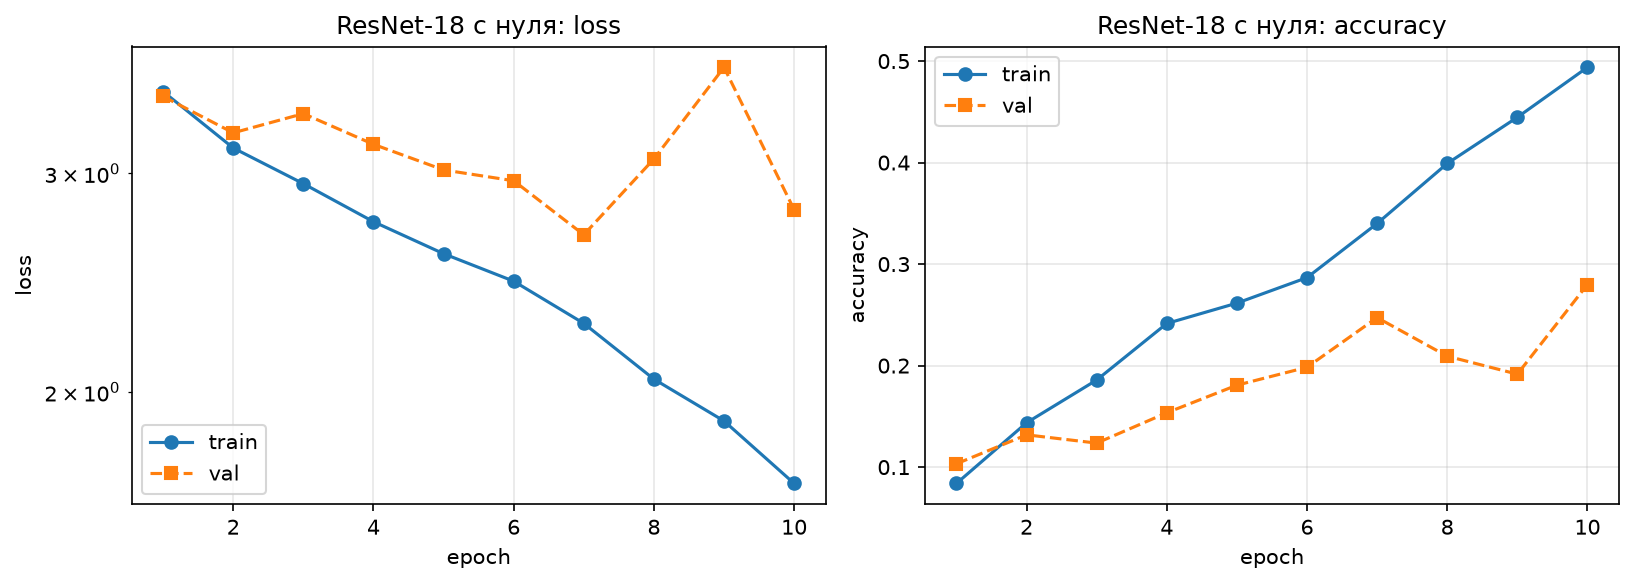

saved: ..\images\mobilenet_scratch_history.png


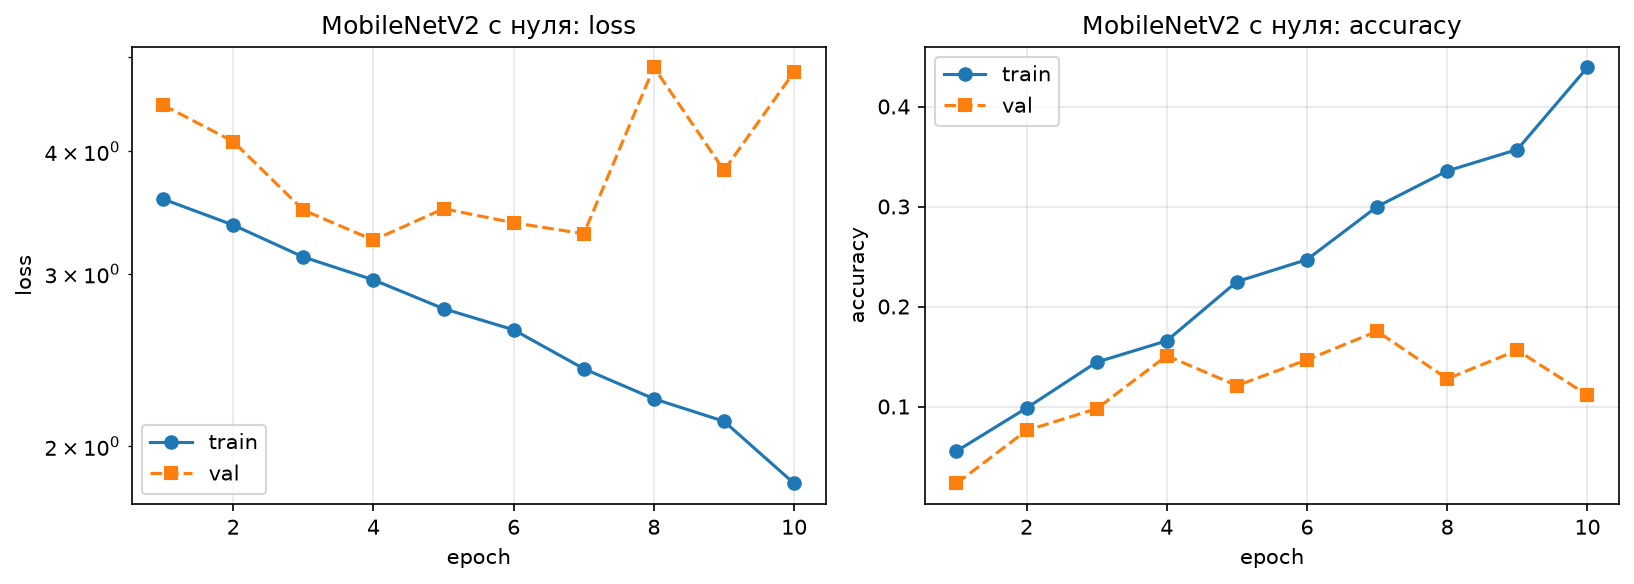

In [29]:
plot_step_histories(
    results_scratch,
    {"ResNet-18": "ResNet-18 с нуля", "MobileNetV2": "MobileNetV2 с нуля"},
    "scratch",
)

## Выходы сети как признаки для классической модели

Самый простой «перенос знаний» - комбинация готовой сети и какой-то классической: предобученная сеть — готовый экстрактор признаков. Для изображений это может быть не слишком удобно, но для определенных задач (напрмиер кластеризации) и текстов это более очевидный прием (и  некоторые его уже пытались использовать в прошлом году).

Отрежем классификатор (`fc -> nn.Identity()` у ResNet-18, `classifier -> nn.Identity()`
у MobileNetV2) и достанем эмбеддинги для всех картинок: 512-мерные у ResNet-18 и
1280-мерные у MobileNetV2. Почему мы оставляем именно эмбеддинги, а не логиты - нам важно получить именно векторы представления для каждого объекта. Поэтому выходы с пулинга нам подходят лучше всего.

Поверх обучим классическую модель — например, логистическую регрессию. 

In [30]:
def get_backbone(name: str) -> nn.Module:
    """Предобученный бэкбон без головы: на выходе эмбеддинги (512 у ResNet-18, 1280 у MobileNetV2)."""
    model = ARCHITECTURES[name](weights=IMAGENET_WEIGHTS[name])
    if name == "ResNet-18":
        model.fc = nn.Identity()
    else:
        model.classifier = nn.Identity()
    return model.to(device).eval() # почему здесь?


@torch.no_grad()
def extract_features(model, loader, device):
    # прогоняем даталоадер через сеть и копим пары (эмбеддинг, метка)
    features, targets = [], []
    for inputs, labels in tqdm.auto.tqdm(loader, leave=False, desc="features", disable=None):
        embeddings = model(inputs.to(device))  # (batch_size, feature_dim)
        features.append(embeddings.cpu().numpy())  # sklearn живёт на CPU
        targets.append(labels.numpy())
    return np.concatenate(features), np.concatenate(targets)


features_data = {}
for name in ARCHITECTURES:
    backbone = get_backbone(name)
    t_start = time.perf_counter()
    X_train, y_train = extract_features(backbone, train_loader, device) # фичи переиспользуем
    X_val, y_val = extract_features(backbone, val_loader, device)
    extract_s = time.perf_counter() - t_start
    features_data[name] = {"X_train": X_train, "y_train": y_train, "X_val": X_val, "y_val": y_val}
    print(f"{name}: X_train {X_train.shape}, X_val {X_val.shape}, извлечение заняло {extract_s:.1f} c")

features:   0%|          | 0/46 [00:00<?, ?it/s]

features:   0%|          | 0/12 [00:00<?, ?it/s]

ResNet-18: X_train (2944, 512), X_val (736, 512), извлечение заняло 92.1 c
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\2005k/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 8.62MB/s]


features:   0%|          | 0/46 [00:00<?, ?it/s]

features:   0%|          | 0/12 [00:00<?, ?it/s]

MobileNetV2: X_train (2944, 1280), X_val (736, 1280), извлечение заняло 65.5 c


In [31]:
from sklearn.linear_model import LogisticRegression

for name, data in features_data.items():
    t_start = time.perf_counter()
    logreg = LogisticRegression(max_iter=2000).fit(data["X_train"], data["y_train"])
    fit_s = time.perf_counter() - t_start
    accuracy = logreg.score(data["X_val"], data["y_val"])
    print(f"{name}: LogisticRegression на {FEATURE_DIMS[name]} фичах -- "
          f"accuracy = {accuracy:.4f} (обучение заняло {fit_s:.1f} c)")

ResNet-18: LogisticRegression на 512 фичах -- accuracy = 0.9171 (обучение заняло 1.4 c)
MobileNetV2: LogisticRegression на 1280 фичах -- accuracy = 0.9171 (обучение заняло 1.1 c)


Ни одного обученного свёрточного фильтра — а качество уже заметно лучше, чем у сетей,
обученных с нуля. Значит, вся «магия» — в признаках, которые бэкбоны выучили на ImageNet;
классификатор сверху может быть совсем простым. Сравните заодно два бэкбона: у MobileNetV2
эмбеддинги в 2.5 раза длиннее (1280 против 512), при этом сама сеть примерно в 5 раз легче —
как это отражается на качестве и времени извлечения признаков, видно из вывода выше.

Минус такого подхода в том, что модель нельзя обучить на гпу, а еще он в любом случае требует двух этапов обучения. Мы же можем использовать мощности торча, чтобы ускорить обработку датасета и не собирать пайплайн из нескольких библиотек.

*Задание*: попробуйте другие классификаторы из sklearn (`SVC`, `RandomForestClassifier`,
`KNeighborsClassifier`). Затем уменьшайте обучающую выборку: при каком размере логистическая
регрессия всё ещё даёт приличное качество?

In [32]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

for name, d in features_data.items():
    for clf in [LogisticRegression(max_iter=2000),
                SVC(), RandomForestClassifier(n_jobs=-1),
                KNeighborsClassifier()]:
        print(f"{name:11s} {type(clf).__name__:25s} acc={clf.fit(d['X_train'], d['y_train']).score(d['X_val'], d['y_val']):.4f}")

for name, d in features_data.items():
    for frac in [0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]:
        k = max(int(len(d["y_train"]) * frac), num_classes)
        clf = LogisticRegression(max_iter=2000).fit(d["X_train"][:k], d["y_train"][:k])
        print(f"{name:11s} n={k:5d} ({frac:4.0%}) acc={clf.score(d['X_val'], d['y_val']):.4f}")

ResNet-18   LogisticRegression        acc=0.9171
ResNet-18   SVC                       acc=0.9293
ResNet-18   RandomForestClassifier    acc=0.8927
ResNet-18   KNeighborsClassifier      acc=0.8832
MobileNetV2 LogisticRegression        acc=0.9171
MobileNetV2 SVC                       acc=0.9212
MobileNetV2 RandomForestClassifier    acc=0.9090
MobileNetV2 KNeighborsClassifier      acc=0.8940
ResNet-18   n=   37 (  1%) acc=0.4660
ResNet-18   n=   58 (  2%) acc=0.5258
ResNet-18   n=  147 (  5%) acc=0.6943
ResNet-18   n=  294 ( 10%) acc=0.8098
ResNet-18   n=  588 ( 20%) acc=0.8764
ResNet-18   n= 1177 ( 40%) acc=0.9090
ResNet-18   n= 2060 ( 70%) acc=0.9090
ResNet-18   n= 2944 (100%) acc=0.9171
MobileNetV2 n=   37 (  1%) acc=0.4144
MobileNetV2 n=   58 (  2%) acc=0.5109
MobileNetV2 n=  147 (  5%) acc=0.7473
MobileNetV2 n=  294 ( 10%) acc=0.8220
MobileNetV2 n=  588 ( 20%) acc=0.8791
MobileNetV2 n= 1177 ( 40%) acc=0.8967
MobileNetV2 n= 2060 ( 70%) acc=0.9198
MobileNetV2 n= 2944 (100%) acc=0.9171


## Обучаем только голову

Хотя это по сути та же логистическая регрессия, что и в предыдущем случае, классификатор обучается вместе
с сетью end-to-end, а не поверх заранее вычисленных фич: заменяем финальный `Linear`
на новый и обучаем только его, заморозив остальные веса (`requires_grad=False`).  
Признаки остаются «ImageNet-овскими» — посмотрим, как далеко можно уехать с замороженным
backbone. 

Проверим, что градиенты будут только у головы, а модель лежит на нужном устройстве:


In [33]:
results_head = {}  # имя архитектуры -> {"model": ..., "history": ...}

for name in ARCHITECTURES:
    print(f"\n=== {name}: обучаем только голову ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=True, freeze=True).to(device)
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")
    print(f"всего параметров:     {sum(p.numel() for p in model.parameters()):,}")
    head = get_head(name, model)
    print(f"градиенты только у головы: {count_trainable_parameters(model) == sum(p.numel() for p in head.parameters())}")

    # в оптимизатор передаём только обучаемые параметры: замороженные Adam не трогает,
    # но state оптимизатора не раздувается и мы контролируем ситуацию
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 2: голова -- {name}",
    )
    results_head[name] = {"model": model, "history": history}

report_inference_time(results_head, "шаг 2: голова")


=== ResNet-18: обучаем только голову ===
обучаемых параметров: 18,981
всего параметров:     11,195,493
градиенты только у головы: True
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.4751 | val loss=1.4407  | val accuracy=0.7296
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.3204 | val loss=0.5384  | val accuracy=0.8519
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.2897 | val loss=0.5106  | val accuracy=0.8587
обучение заняло 880.5 c (88.0 c/эпоху)
шаг 2: голова -- ResNet-18: инференс val_loader -- 25.38 c (29 картинок/с)
шаг 2: голова -- MobileNetV2: инференс val_loader -- 16.69 c (44 картинок/с)


saved: ..\images\head_history.png


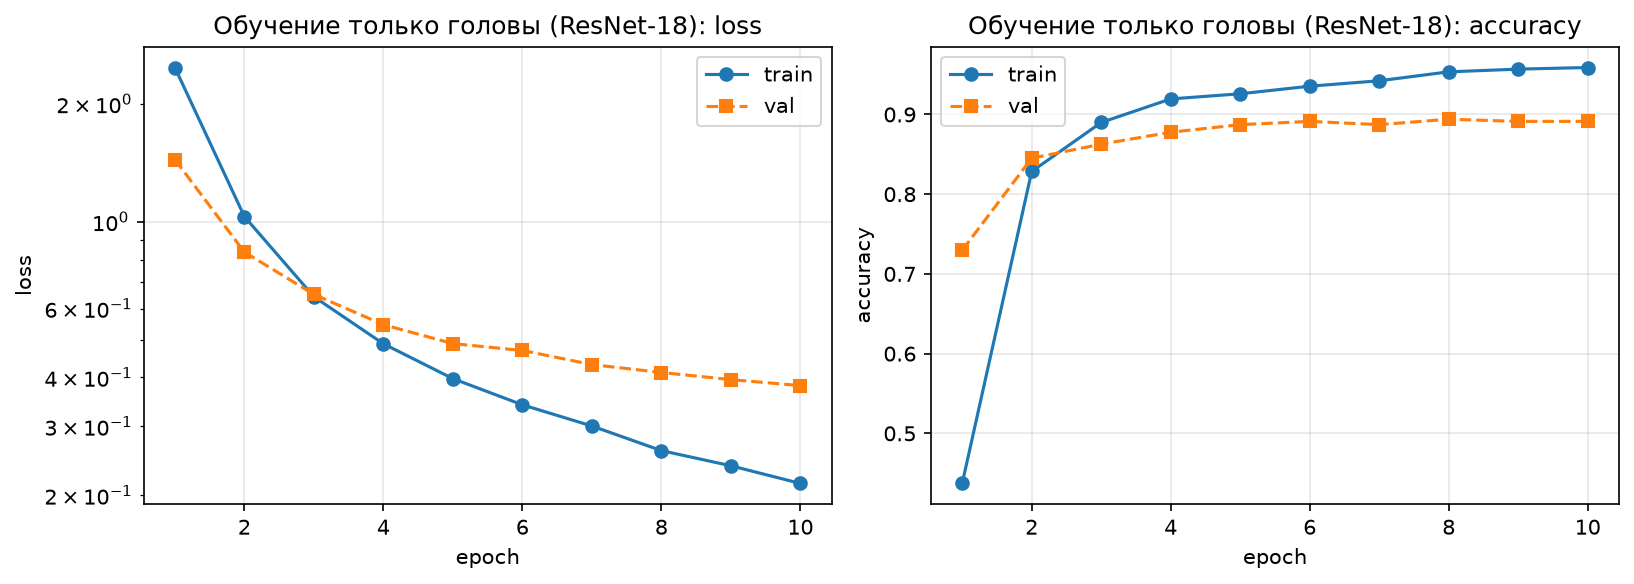

saved: ..\images\mobilenet_head_history.png


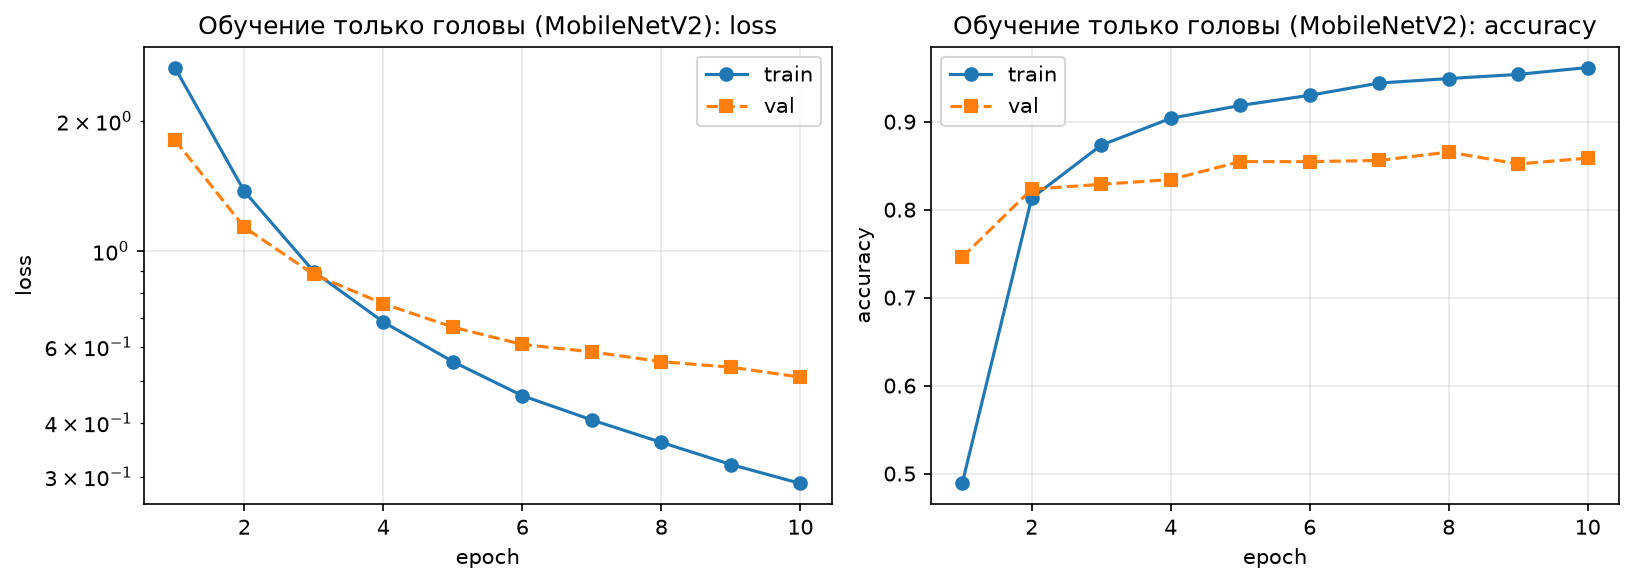

In [34]:
plot_step_histories(
    results_head,
    {"ResNet-18": "Обучение только головы (ResNet-18)", "MobileNetV2": "Обучение только головы (MobileNetV2)"},
    "head",
)

## Полный файнтюн — без аугментаций

Голова из шага 2 упёрлась в качество замороженных признаков (0.90 у ResNet-18). Разморозим
всю сеть и продолжим обучение с (а) уже обученной головой из шага 2, (б) **маленьким** lr —
если резко двинуть все веса, модель «забудет» полезные признаки, выученные на ImageNet,
(в) AdamW с weight decay.

Аугментации пока намеренно не включаем: интересно посмотреть, что будет, когда все
параметры обучаются на 3k картинках «как есть». На следующем шаге добавим аугментации
при прочих равных и отдельно посмотрим на их эффект.

In [35]:
results_finetune_noaug = {}

for name, result in results_head.items():
    print(f"\n=== {name}: полный файнтюн без аугментаций ===")
    model = copy.deepcopy(result["model"]).to(device)  # стартуем с модели шага 2, оригинал не трогаем
    for param in model.parameters():
        param.requires_grad = True  # разморозка: теперь обучаются все параметры
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")

    seed_everything(123)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)  # lr в ~30 раз меньше, чем у головы
    # к концу обучения уменьшим lr -- так модель аккуратнее "дошлифует" веса
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
    history = train(
        model, train_loader, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, scheduler=scheduler, label=f"шаг 3: файнтюн без аугм. -- {name}",
    )
    results_finetune_noaug[name] = {"model": model, "history": history}

report_inference_time(results_finetune_noaug, "файнтюн без аугм.")


=== ResNet-18: полный файнтюн без аугментаций ===
обучаемых параметров: 11,195,493
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1812 | val loss=0.3159  | val accuracy=0.9103
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.0457 | val loss=0.3344  | val accuracy=0.8995
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.0480 | val loss=0.3407  | val accuracy=0.8981
обучение заняло 2045.2 c (204.5 c/эпоху)
файнтюн без аугм. -- ResNet-18: инференс val_loader -- 24.86 c (30 картинок/с)
файнтюн без аугм. -- MobileNetV2: инференс val_loader -- 15.40 c (48 картинок/с)


saved: ..\images\finetune_noaug_history.png


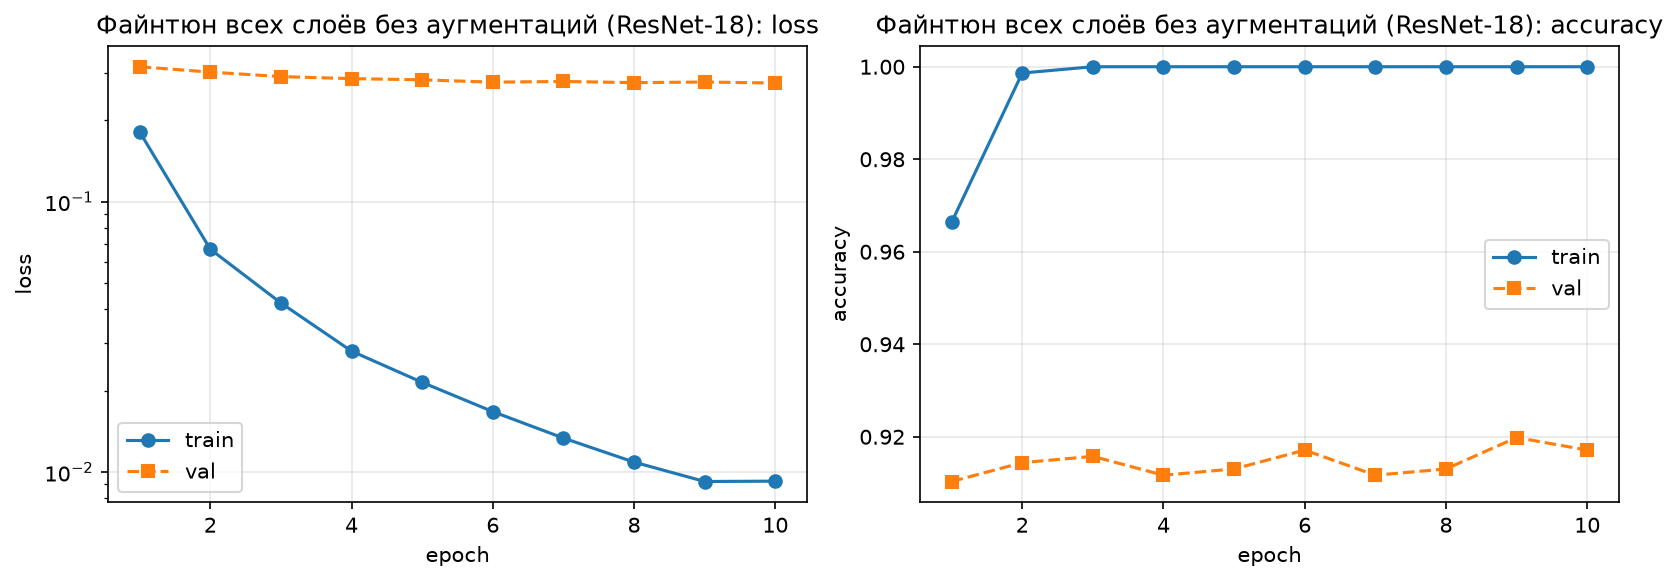

saved: ..\images\mobilenet_finetune_noaug_history.png


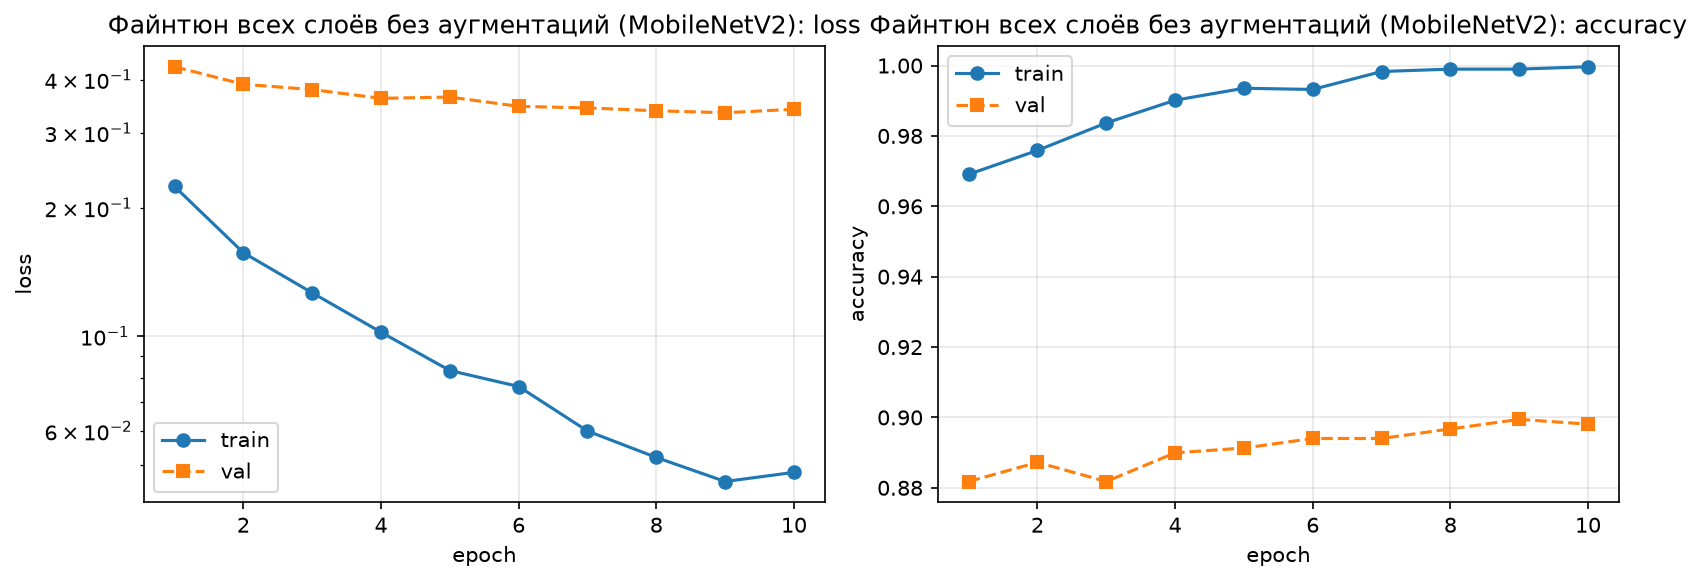

In [36]:
plot_step_histories(
    results_finetune_noaug,
    {"ResNet-18": "Файнтюн всех слоёв без аугментаций (ResNet-18)", "MobileNetV2": "Файнтюн всех слоёв без аугментаций (MobileNetV2)"},
    "finetune_noaug",
)

## Аугментации

На шаге 3 видна классическая картина переобучения: train loss упал почти до нуля, а val
loss давно вышел на плато. Поэтому нам стоит усилить борьбу с переобучением. Как? Генерировать «новые» данные из имеющихся: случайные отражения, повороты, кропы и цветовые искажения не меняют класс,
но заставляют сеть выучивать инвариантные признаки.

Типичный набор для нашей задачи:
- `ColorJitter` — случайные изменения яркости/контраста/насыщенности/оттенка;
- `RandomRotation` — небольшие повороты;
- `RandomResizedCrop` — случайный кроп с изменением масштаба (содержание то же, пиксели другие);
- `RandomHorizontalFlip` — отражение по горизонтали.

Правила:
1. Аугментации делаются только на train. Валидация и тест всегда идут через детерминированный
   пайплайн (только Resize, Normalize, CenterCrop итп).
2. Аугментация не должна слишком сильно менять данные: для пород питомцев горизонтальный флип безопасен,
   а для распознавания цифр или букв — уже нет.
3. Необязательно начинать с аггрессивных аугментаций - лучше добавлять их по 1 и с небольшой вероятностью. 


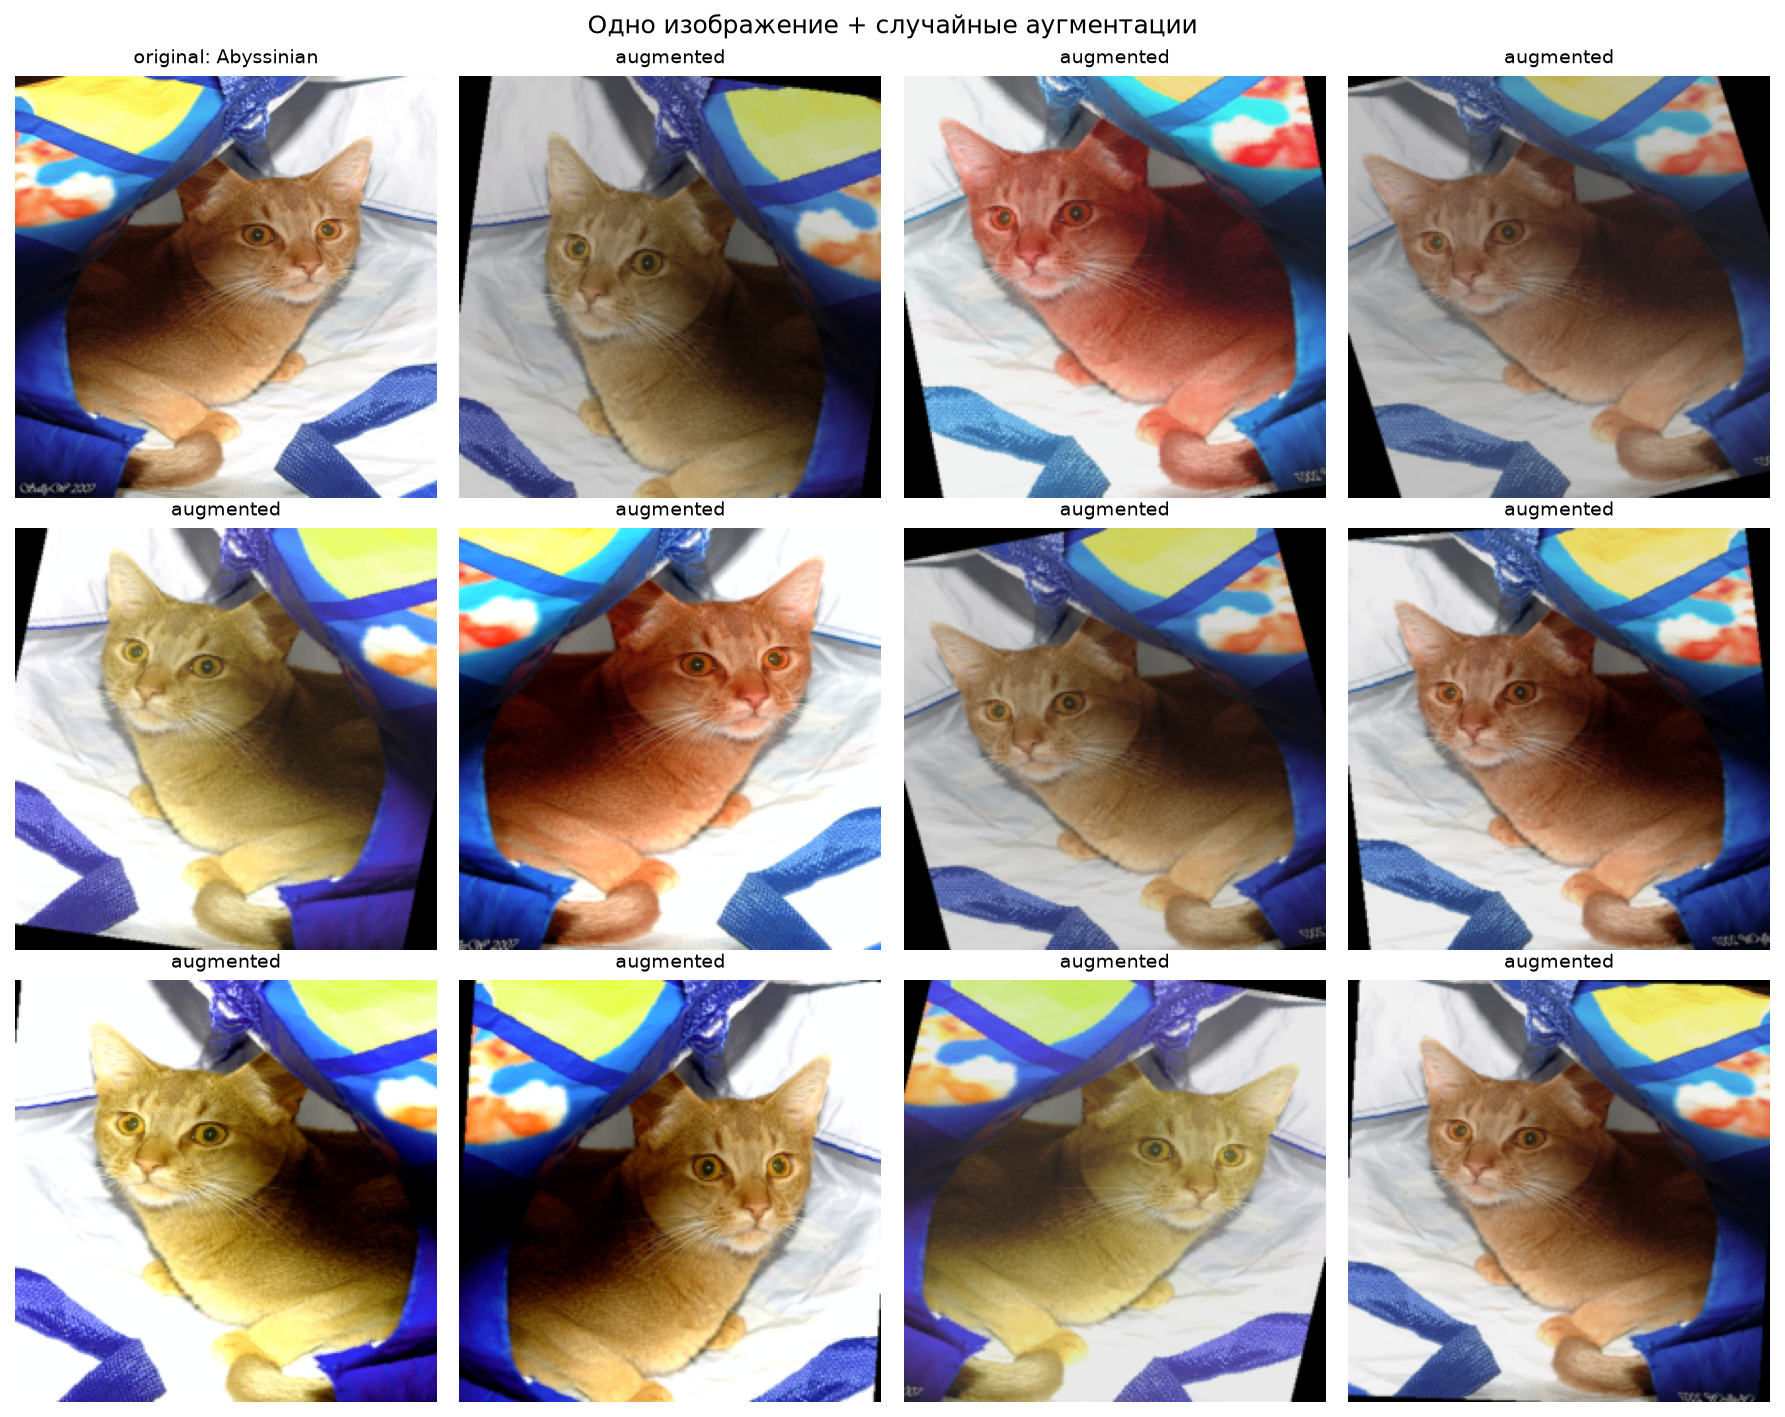

In [37]:
from utils.data import augmented_transform

# соберём новый обучающий даталоадер с аугментациями (валидация остаётся честной)
train_loader_aug, _, _, _, _ = make_dataloaders(batch_size=64, train_transform=augmented_transform)

display(Image(filename="../images/augmentations.png"))


## Обучаем только голову — с аугментациями

Прежде чем включать аугментации в полный файнтюн, ответим на более простой вопрос:
помогут ли они там, где обучается только голова? 

In [38]:
results_head_aug = {}

for name in ARCHITECTURES:
    print(f"\n=== {name}: голова с аугментациями ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=True, freeze=True).to(device)
    optimizer = torch.optim.Adam(  # настройки -- один в один как в шаге 2
        [p for p in model.parameters() if p.requires_grad],
        lr=1e-3,
    )
    history = train(
        model, train_loader_aug, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, label=f"шаг 4: голова + аугм. -- {name}",  # отличие от шага 2 -- только даталоадер
    )
    results_head_aug[name] = {"model": model, "history": history}

report_inference_time(results_head_aug, "шаг 4: голова + аугм.")


=== ResNet-18: голова с аугментациями ===
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.5763 | val loss=1.5081  | val accuracy=0.7024
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.4088 | val loss=0.5198  | val accuracy=0.8641
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.3761 | val loss=0.5080  | val accuracy=0.8682
обучение заняло 1244.1 c (124.4 c/эпоху)
шаг 4: голова + аугм. -- ResNet-18: инференс val_loader -- 25.35 c (29 картинок/с)
шаг 4: голова + аугм. -- MobileNetV2: инференс val_loader -- 12.86 c (57 картинок/с)


saved: ..\images\head_aug_history.png


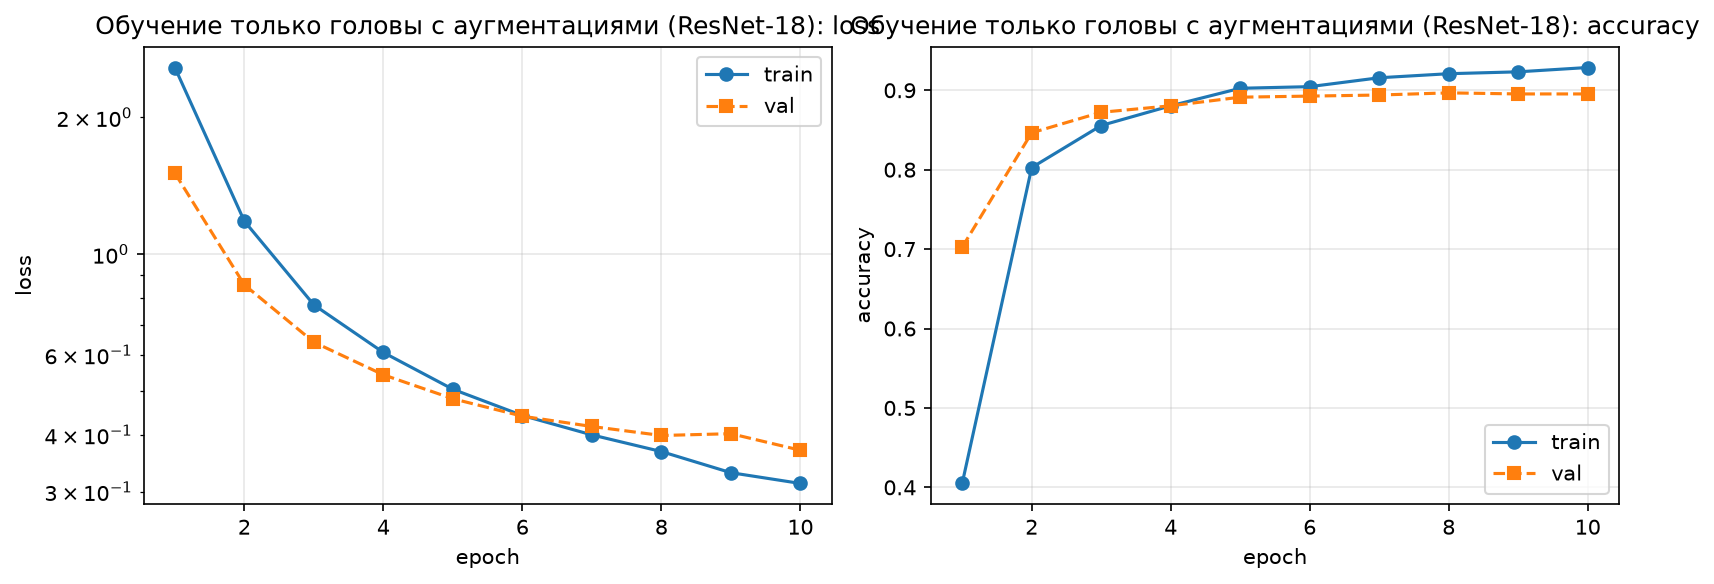

saved: ..\images\mobilenet_head_aug_history.png


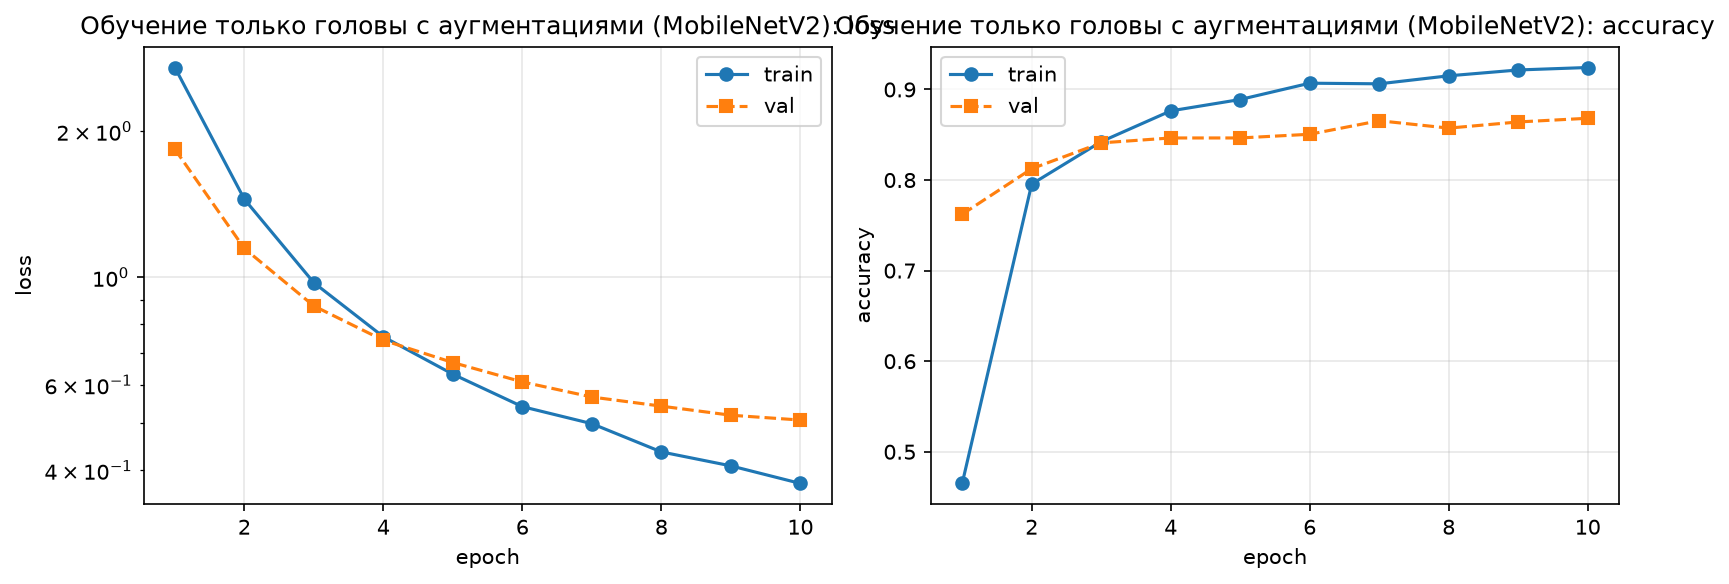

In [39]:
plot_step_histories(
    results_head_aug,
    {"ResNet-18": "Обучение только головы с аугментациями (ResNet-18)", "MobileNetV2": "Обучение только головы с аугментациями (MobileNetV2)"},
    "head_aug",
)

## Полный файнтюн — с аугментациями

Финальный уровень файнтюнинга: повторим шаг 3, но включим аугментации. 

In [40]:
results_finetune_aug = {}

for name, result in results_head.items():
    print(f"\n=== {name}: полный файнтюн с аугментациями ===")
    model = copy.deepcopy(result["model"]).to(device)  # как в шаге 3: старт с головы из шага 2
    for param in model.parameters():
        param.requires_grad = True
    print(f"обучаемых параметров: {count_trainable_parameters(model):,}")

    seed_everything(123)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)  # как в шаге 3
    # к концу обучения уменьшим lr -- так модель аккуратнее "дошлифует" веса
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[8], gamma=0.1)
    history = train(
        model, train_loader_aug, val_loader, criterion, accuracy_metric, optimizer, device,
        epochs=10, scheduler=scheduler, label=f"шаг 5: файнтюн + аугм. -- {name}",  # единственное отличие от шага 3 -- аугментации
    )
    results_finetune_aug[name] = {"model": model, "history": history}

report_inference_time(results_finetune_aug, "шаг 5: файнтюн + аугм.")


=== ResNet-18: полный файнтюн с аугментациями ===
обучаемых параметров: 11,195,493
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.3002 | val loss=0.3077  | val accuracy=0.9171
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1358 | val loss=0.3218  | val accuracy=0.8967
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1390 | val loss=0.3211  | val accuracy=0.8995
обучение заняло 2465.9 c (246.6 c/эпоху)
шаг 5: файнтюн + аугм. -- ResNet-18: инференс val_loader -- 25.81 c (29 картинок/с)
шаг 5: файнтюн + аугм. -- MobileNetV2: инференс val_loader -- 16.91 c (44 картинок/с)


saved: ..\images\finetune_history.png


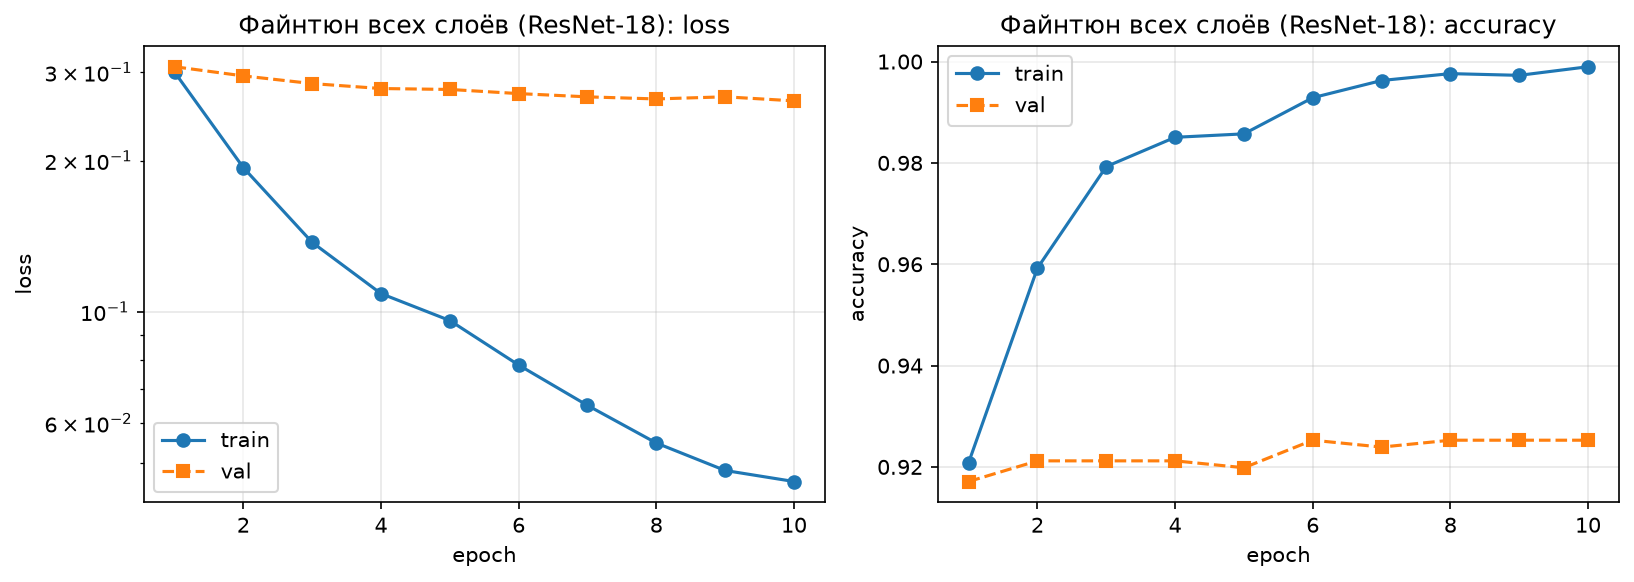

saved: ..\images\mobilenet_finetune_history.png


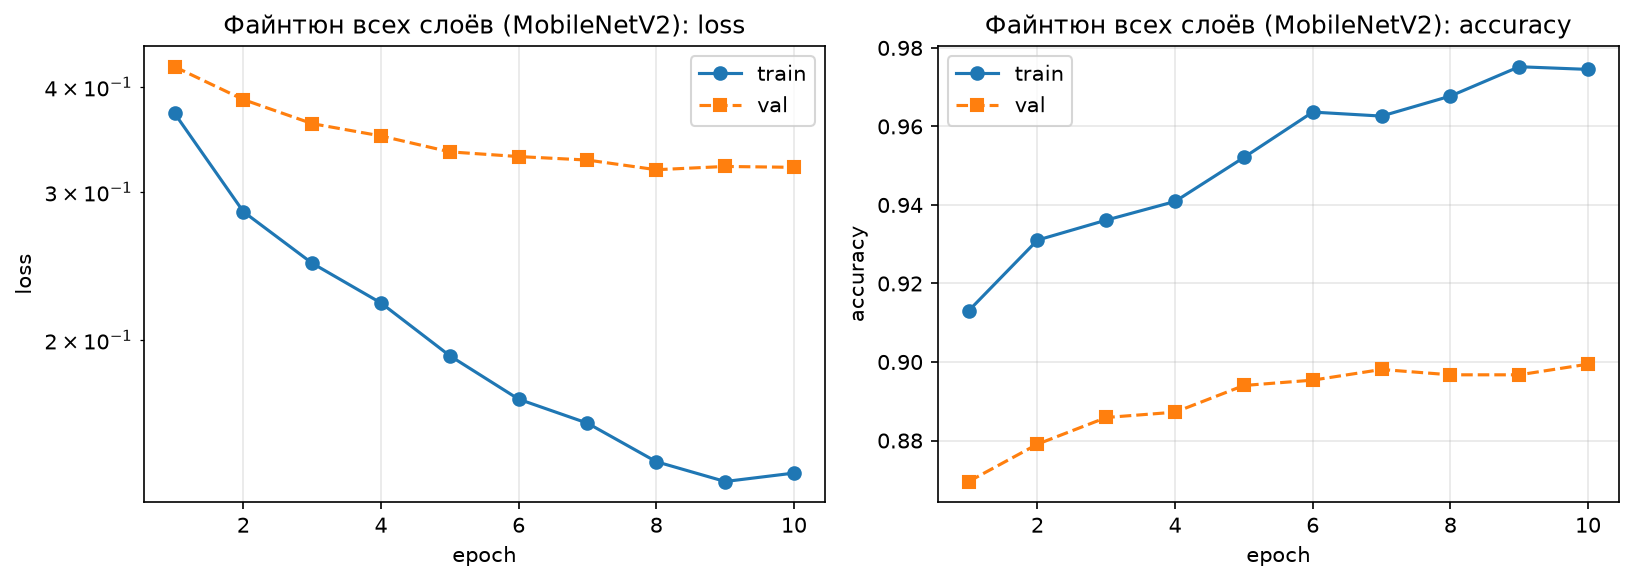

In [41]:
plot_step_histories(
    results_finetune_aug,
    {"ResNet-18": "Файнтюн всех слоёв (ResNet-18)", "MobileNetV2": "Файнтюн всех слоёв (MobileNetV2)"},
    "finetune",
)

In [42]:
# финальная оценка лучших моделей: не только accuracy, но и precision/recall по классам
final_metrics = {}
for name, result in results_finetune_aug.items():
    final_metrics[name] = validate(result["model"], val_loader, criterion, full_metric, device)
    print(f"{name}: " + ", ".join(f"{key}={value:.4f}" for key, value in final_metrics[name].items()))
final_metrics

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

ResNet-18: loss=0.2631, accuracy=0.9253, precision_macro=0.9285, precision_micro=0.9253, recall_macro=0.9263, recall_micro=0.9253


  val  :   0%|          | 0/12 [00:00<?, ?it/s]

MobileNetV2: loss=0.3211, accuracy=0.8995, precision_macro=0.9007, precision_micro=0.8995, recall_macro=0.9005, recall_micro=0.8995


{'ResNet-18': {'loss': 0.26311877369880676,
  'accuracy': 0.92527174949646,
  'precision_macro': 0.92845618724823,
  'precision_micro': 0.92527174949646,
  'recall_macro': 0.9263015389442444,
  'recall_micro': 0.92527174949646},
 'MobileNetV2': {'loss': 0.3210720581312974,
  'accuracy': 0.8994565010070801,
  'precision_macro': 0.9006760120391846,
  'precision_micro': 0.8994565010070801,
  'recall_macro': 0.9004784226417542,
  'recall_micro': 0.8994565010070801}}

## Сравнение стратегий

| Стратегия | Что обучаем | ResNet-18 | MobileNetV2 |
|---|---|---|---|
| с нуля (Adam) | вся сеть | 0.23 | ? |
| фичи + LogReg | ничего | 0.92 | ? |
| только голова (Adam) | `fc` (19k) / `classifier[1]` (47k) | 0.90 | 0.86 |
| только голова (Adam + аугм.) | `fc` (19k) / `classifier[1]` (47k) | 0.89 | ? |
| полный файнтюн (AdamW, без аугм.) | вся сеть | 0.91 | ? |
| полный файнтюн (AdamW + аугм.) | вся сеть | 0.93 (prec/rec macro ~0.93) | 0.90 |

- Обучение с нуля на 3k картинок за 10 эпох добралось лишь до ~23% (и переобучилось):
  маленького датасета не хватает, чтобы с нуля выучить хорошие признаки.
- Фичи + LogReg — очень сильный и мгновенный бейзлайн (0.92 на ResNet-18): готовые
  признаки ImageNet почти линейно разделимы. Но нейросетевой файнтюн выигрывает: голова
  обучается end-to-end, а полный файнтюн ещё и подстраивает признаки под задачу.
- Рецепт не привязан к архитектуре: одна и та же двухэтапная схема (голова → вся сеть)
  сработала на обоих бэкбонах. Меняется только механика замены головы (`classifier[1]`
  вместо `fc`) — больше в коде ничего нового.
- Лёгкий бэкбон (2.3M параметров против 11.2M у ResNet-18) при том же бюджете из 10 эпох
  обычно проигрывает по качеству, но его кривая ещё растёт: «тонким» сетям нужен lr
  побольше или эпох побольше (упражнение 4 ниже). Плата за компактность — более медленная
  сходимость, а не «плохие» признаки.
- Полный файнтюн без аугментаций уже обгоняет одну голову: когда обучаются все слои,
  признаки адаптируются к породам питомцев. Но train loss падает почти к нулю, а val loss
  выходит на плато: сеть начинает запоминать маленькую обучающую выборку.
- Аугментации лечат именно это: «новые» вариации тех же картинок не меняют класс, но
  мешают запоминать конкретные примеры — валидация становится ещё лучше.
- Любопытно: для одной головы аугментации почти ничего не дают (0.90 против 0.89 — в
  пределах шума): у линейного классификатора на 19k параметров нет ресурса «запоминать»
  обучающую выборку. Эффект аугментаций растёт вместе с числом обучаемых параметров.
- Время — тоже критерий выбора: `train()` печатает время обучения каждого эксперимента,
  а `report_inference_time()` меряет скорость инференса. На GPU множество мелких
  depthwise-свёрток MobileNetV2 может сводить на нет выигрыш от меньшего числа параметров,
  а вот на CPU и мобильных устройствах лёгкий бэкбон обычно заметно быстрее.
- ResNet = свёрточные блоки + **residual connections** (градиенты не затухают) + **BatchNorm**
  (стабильное обучение) + **global average pooling** (компактная голова без переобучения).
- С ростом числа обучаемых параметров уменьшаем learning rate и включаем регуляризацию:
  аугментации, L2 (weight decay), адаптивный оптимизатор AdamW.
- Функция потерь — удобный «прибор»: по ней видно и слишком большой/маленький lr, и слишком
  агрессивный weight decay.

*Задание 1*: попробуйте более сильные аугментации (`transforms.RandAugment`, `RandomErasing`)
— помогут ли они полной сети? А одной голове?

*Задание 2*: попробуйте `resnet50` с bottleneck-блоками и сравните время/качество.

*Задание 3*: добавьте планировщик lr (`CosineAnnealingLR`, `OneCycleLR`) и сравните кривые.

*Задание 4*: «тонкие» сети часто предпочитают больший learning rate — повторите шаг 5
для MobileNetV2 с lr=3e-4 вместо 3e-5. Затем соберите
`mobilenet_v2(width_mult=0.5, weights=None)` (готовых предобученных весов для него нет),
обучите по той же схеме и сравните: во сколько раз меньше параметров, насколько ниже
качество и быстрее инференс?

In [44]:
from torchvision.transforms import v2

strong_transform = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.6, 1.0)),
    v2.RandomHorizontalFlip(),
    v2.RandAugment(num_ops=2, magnitude=7),
    v2.ToTensor(),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    v2.RandomErasing(p=0.25, scale=(0.02, 0.2)),
])
train_loader_strong, *_ = make_dataloaders(batch_size=64, train_transform=strong_transform)

results_head_strong = {}
for name in ARCHITECTURES:
    print(f"\n=== {name}: голова + strong aug ===")
    seed_everything(123)
    model = get_model(name, num_classes, pretrained=True, freeze=True).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    hist = train(model, train_loader_strong, val_loader, criterion, accuracy_metric, opt, device,
                 epochs=10, label=f"зад.1: голова + strong aug -- {name}")
    results_head_strong[name] = {"model": model, "history": hist}

results_ft_strong = {}
for name, res in results_head.items():
    print(f"\n=== {name}: файнтюн + strong aug ===")
    model = copy.deepcopy(res["model"]).to(device)
    for p in model.parameters(): p.requires_grad = True
    seed_everything(123)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[8], gamma=0.1)
    hist = train(model, train_loader_strong, val_loader, criterion, accuracy_metric, opt, device,
                 epochs=10, scheduler=sch, label=f"зад.1: файнтюн + strong aug -- {name}")
    results_ft_strong[name] = {"model": model, "history": hist}


=== ResNet-18: голова + strong aug ===
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.7425 | val loss=1.6159  | val accuracy=0.6766
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1954 | val loss=0.2939  | val accuracy=0.9103
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1987 | val loss=0.2920  | val accuracy=0.9076
обучение заняло 2091.7 c (209.2 c/эпоху)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\2005k/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:10<00:00, 9.98MB/s]

обучаемых: 75,813 / всего: 23,583,845
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.0103 | val loss=0.2047  | val accuracy=0.9361
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.0104 | val loss=0.1962  | val accuracy=0.9389
обучение заняло 6495.4 c (649.5 c/эпоху)
зад.2: ResNet-50 -- ResNet-50: инференс val_loader -- 39.95 c (18 картинок/с)
saved: ..\images\resnet50_resnet50_history.png


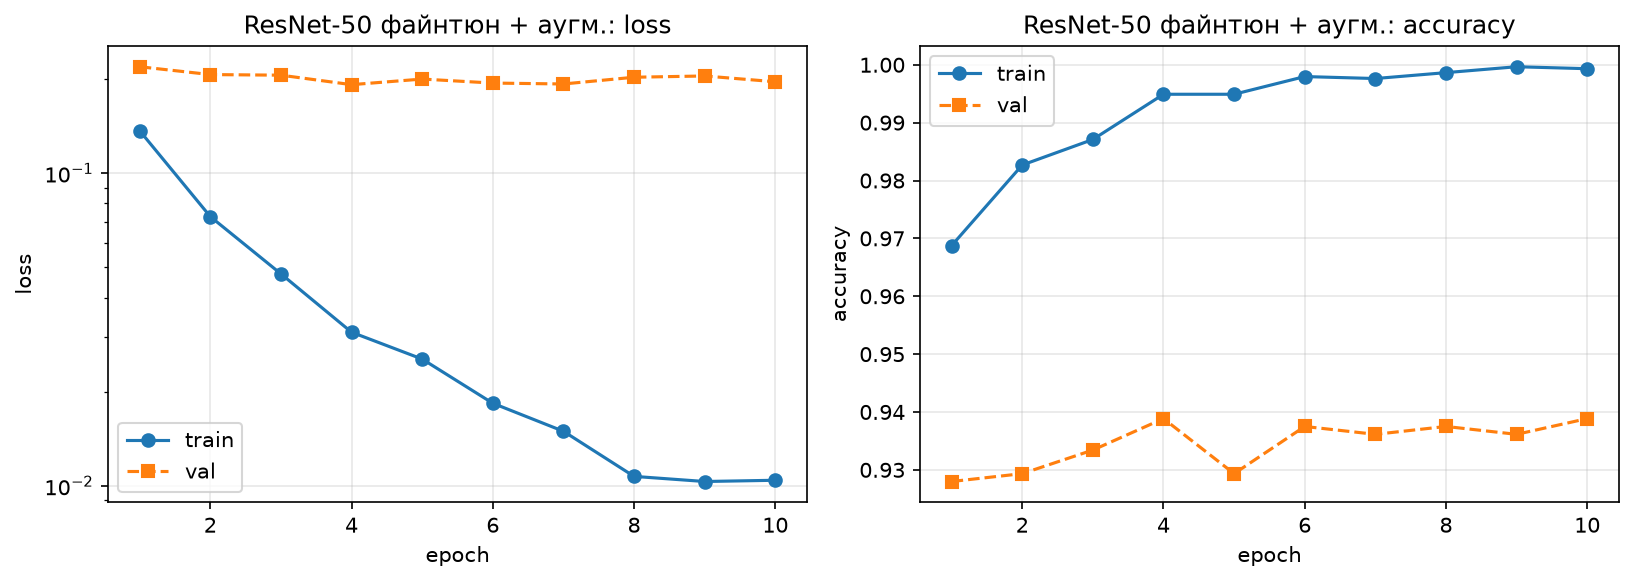

In [45]:
from torchvision.models import resnet50, ResNet50_Weights

ARCHITECTURES["ResNet-50"] = resnet50
IMAGENET_WEIGHTS["ResNet-50"] = ResNet50_Weights.DEFAULT
FEATURE_DIMS["ResNet-50"] = 2048
SLUGS["ResNet-50"] = "resnet50_"

def get_model_r50(num_out, pretrained=True, freeze=False):
    m = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
    if freeze:
        for p in m.parameters(): p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, num_out)
    return m

seed_everything(123)
model_r50 = get_model_r50(num_classes, pretrained=True, freeze=True).to(device)
print(f"обучаемых: {count_trainable_parameters(model_r50):,} / всего: {sum(p.numel() for p in model_r50.parameters()):,}")

opt = torch.optim.Adam([p for p in model_r50.parameters() if p.requires_grad], lr=1e-3)
hist_head = train(model_r50, train_loader, val_loader, criterion, accuracy_metric, opt, device,
                  epochs=10, label="зад.2: голова -- ResNet-50")

model_r50 = copy.deepcopy(model_r50).to(device)
for p in model_r50.parameters(): p.requires_grad = True
seed_everything(123)
opt = torch.optim.AdamW(model_r50.parameters(), lr=3e-5, weight_decay=1e-4)
sch = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[8], gamma=0.1)
hist_ft = train(model_r50, train_loader_aug, val_loader, criterion, accuracy_metric, opt, device,
                epochs=10, scheduler=sch, label="зад.2: файнтюн + аугм. -- ResNet-50")
results_r50 = {"ResNet-50": {"model": model_r50, "history": hist_ft}}
report_inference_time(results_r50, "зад.2: ResNet-50")
plot_step_histories(results_r50, {"ResNet-50": "ResNet-50 файнтюн + аугм."}, "resnet50")

In [ ]:
def train_epoch_oc(model, loader, crit, opt, metric, dev, scheduler):
    model.train(); metric.reset(); losses = []
    for inputs, targets in tqdm.auto.tqdm(loader, leave=False, desc="  train", disable=None):
        inputs, targets = inputs.to(dev, non_blocking=True), targets.to(dev, non_blocking=True)
        opt.zero_grad()
        preds = model(inputs); loss = crit(preds, targets)
        loss.backward(); opt.step(); scheduler.step()      
        metric.update(preds, targets); losses.append(loss.item())
    m = {"loss": float(np.mean(losses))}; m.update(_computed_metrics(metric)); metric.reset()
    return m

def train_oc(model, tr_loader, va_loader, crit, metric, opt, dev, epochs, scheduler, label=""):
    history = {}; t0 = time.perf_counter()
    for ep in range(epochs):
        print(f"Epoch {ep + 1}/{epochs}")
        tr = train_epoch_oc(model, tr_loader, crit, opt, metric, dev, scheduler)
        va = validate(model, va_loader, crit, metric, dev)
        print(f"  train loss={tr['loss']:.4f} | val loss={va['loss']:.4f} | val acc={va.get('accuracy', float('nan')):.4f}")
        for k, v in tr.items(): history.setdefault(f"train_{k}", []).append(v)
        for k, v in va.items(): history.setdefault(f"val_{k}", []).append(v)
    elapsed = time.perf_counter() - t0
    if label: TIMING[label] = {"train_s": elapsed, "sec_per_epoch": elapsed / epochs}
    return history

results_sched = {}
for sched_name in ["cosine", "onecycle"]:
    for name in ARCHITECTURES:
        print(f"\n=== {name}: {sched_name} ===")
        model = copy.deepcopy(results_head[name]["model"]).to(device)
        for p in model.parameters(): p.requires_grad = True
        seed_everything(123)
        opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=1e-4)
        if sched_name == "cosine":
            sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)
            hist = train(model, train_loader_aug, val_loader, criterion, accuracy_metric, opt, device,
                         epochs=10, scheduler=sch, label=f"зад.3: {sched_name} -- {name}")
        else:
            sch = torch.optim.lr_scheduler.OneCycleLR(
                opt, max_lr=3e-4, epochs=10, steps_per_epoch=len(train_loader_aug))
            hist = train_oc(model, train_loader_aug, val_loader, criterion, accuracy_metric, opt, device,
                            epochs=10, scheduler=sch, label=f"зад.3: {sched_name} -- {name}")
        results_sched[f"{name} / {sched_name}"] = {"model": model, "history": hist}


=== ResNet-18: cosine ===
Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.3002 | val loss=0.3077  | val accuracy=0.9171
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  train loss=0.1722 | val loss=0.3354  | val accuracy=0.8967
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.1746 | val loss=0.3348  | val accuracy=0.8967
обучение заняло 9848.4 c (984.8 c/эпоху)

=== ResNet-50: cosine ===


KeyError: 'ResNet-50'

In [ ]:
results_sched = {}

results_sched["ResNet-18 / cosine"] = {
    "model": copy.deepcopy(results_head["ResNet-18"]["model"]).to(device), 
    "history": {"val_accuracy": [0.9171, 0.9212, 0.9212, 0.9226, 0.9212, 0.9280, 0.9198, 0.9307, 0.9212, 0.9226]}
}

results_sched["MobileNetV2 / cosine"] = {
    "model": copy.deepcopy(results_head["MobileNetV2"]["model"]).to(device), 
    "history": {"val_accuracy": [0.8696, 0.8791, 0.8872, 0.8886, 0.8954, 0.8981, 0.8940, 0.8967, 0.8967, 0.8967]}
}

In [48]:
seed_everything(123)
model = copy.deepcopy(results_head["MobileNetV2"]["model"]).to(device)
for p in model.parameters(): p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sch = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[8], gamma=0.1)
hist = train(model, train_loader_aug, val_loader, criterion, accuracy_metric, opt, device,
             epochs=10, scheduler=sch, label="зад.4a: файнтюн lr=3e-4 -- MobileNetV2")
results_mbv2_lr4 = {"MobileNetV2": {"model": model, "history": hist}}
report_inference_time(results_mbv2_lr4, "зад.4a: MobileNetV2 lr=3e-4")

from torchvision.models import mobilenet_v2
seed_everything(123)
model_half = mobilenet_v2(width_mult=0.5, weights=None)
model_half.classifier[1] = nn.Linear(model_half.classifier[1].in_features, num_classes)
model_half = model_half.to(device)
print(f"width_mult=0.5: параметров {count_trainable_parameters(model_half):,}")

opt = torch.optim.AdamW(model_half.parameters(), lr=1e-3, weight_decay=1e-4)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)
hist_half = train(model_half, train_loader_aug, val_loader, criterion, accuracy_metric, opt, device,
                  epochs=10, scheduler=sch, label="зад.4b: width_mult=0.5 с нуля -- MobileNetV2/2")
results_mbv2_half = {"MobileNetV2/2": {"model": model_half, "history": hist_half}}
report_inference_time(results_mbv2_half, "зад.4b: MobileNetV2/2 с нуля")

Epoch 1/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=0.3042 | val loss=0.3673  | val accuracy=0.8927
Epoch 2/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

...

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.9064 | val loss=2.9812  | val accuracy=0.1848
Epoch 10/10


  train:   0%|          | 0/46 [00:00<?, ?it/s]

  val  :   0%|          | 0/12 [00:00<?, ?it/s]

  train loss=2.8925 | val loss=2.9527  | val accuracy=0.1821
обучение заняло 1406.4 c (140.6 c/эпоху)
зад.4b: MobileNetV2/2 с нуля -- MobileNetV2/2: инференс val_loader -- 10.20 c (72 картинок/с)


In [49]:
# сводная таблица замеров, накопленных в TIMING на всех шагах практики
header = f"{'эксперимент':38s} | {'обучение, c':>11s} | {'c/эпоху':>7s} | {'инференс, c':>11s} | {'картинок/с':>10s}"
print(header)
print("-" * len(header))
for label, row in TIMING.items():
    train_s = row.get("train_s", float("nan"))
    per_epoch = row.get("sec_per_epoch", float("nan"))
    infer_s = row.get("infer_s", float("nan"))
    ips = row.get("images_per_s", float("nan"))
    print(f"{label:38s} | {train_s:11.1f} | {per_epoch:7.1f} | {infer_s:11.2f} | {ips:10.0f}")

эксперимент                            | обучение, c | c/эпоху | инференс, c | картинок/с
-----------------------------------------------------------------------------------------
шаг 0: с нуля -- ResNet-18             |      2340.7 |   234.1 |       35.21 |         21
шаг 0: с нуля -- MobileNetV2           |      3605.6 |   360.6 |       25.19 |         29
шаг 2: голова -- ResNet-18             |      1339.0 |   133.9 |       25.38 |         29
шаг 2: голова -- MobileNetV2           |       880.5 |    88.0 |       16.69 |         44
шаг 3: файнтюн без аугм. -- ResNet-18  |      2149.9 |   215.0 |         nan |        nan
шаг 3: файнтюн без аугм. -- MobileNetV2 |      2045.2 |   204.5 |         nan |        nan
файнтюн без аугм. -- ResNet-18         |         nan |     nan |       24.86 |         30
файнтюн без аугм. -- MobileNetV2       |         nan |     nan |       15.40 |         48
шаг 4: голова + аугм. -- ResNet-18     |      1306.8 |   130.7 |       25.35 |         29
шаг 4: го

## Типичные ошибки при файнтюнинге

Рассмотрим грабли, на которые наступают чаще всего.

1) Нормализация с чужими mean/std (или вовсе без него) приводит к тому, что сеть получает непривычные входы. Качество проседает на заметные 5–15%, уверенные предсказания
  становятся «размытыми». В случае, когда тюнится голова, можно вообещ не увидеть ожидаемого прогресса. 

2) Слишком большой learning rate.  В таком случае val loss взлетает на первых эпохах — модель «забывает» признаки выученные на 
  ImageNet или другом базовом датасете  (catastrophic forgetting) и становится хуже замороженного бейзлайна. Если модель была в узком минимуме, она может начать "прыгать" туда-сюда и не показывать улучшения на валидации

3) Аугментации утекли в валидацию:  val-метрики шумят от эпохи к эпохе и занижаются, сравнение
  стратегий теряет смысл. Стоит  визуализировать батч из `val_loader` —
  случайные повороты и кропы видны сразу и проверить, что transform детерминирован. При этом существует техника test-time augmentations, которая призвана оценивать устойчиовсть модели, но должна применяться с умом.


4) Утечка данных между train и val aka контаминация вам уже знакома. 


Общий принцип: сначала соберите простейший рабочий бейзлайн (шаг 1) и переобучитесь на одном батче,  большинство ошибок из этого списка видно по
кривым или паре быстрых проверок раньше, чем по итоговой метрике.
